# Solar Filament Segmentation with a Custom U-Net

Train a custom PyTorch U-Net on 512 x 512 grayscale tiles built from the COCO polygon annotations. The model predicts a binary filament mask. At inference time, full-resolution test images are tiled, predicted, and stitched back together. Connected components are encoded as one competition RLE row per filament.


In [1]:
%pip install -q pycocotools scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Imports and dataset paths
import os
import csv
import gc
import json
import random
import sys
import time
import warnings
from collections import Counter, defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image

# This notebook is configured to require CUDA for model training and inference.
if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch cannot access CUDA in this notebook kernel.\n"
        f"Python interpreter: {sys.executable}\n"
        f"PyTorch version: {torch.__version__}\n"
        f"PyTorch CUDA build: {torch.version.cuda!r} "
        "(None means this is a CPU-only PyTorch build).\n"
        "Install a CUDA-enabled PyTorch build into this same Python environment, "
        "select the project .venv kernel, then restart the kernel."
    )
GPU_DEVICE = torch.device("cuda:0")
torch.cuda.set_device(GPU_DEVICE)
print(f"CUDA GPU: {torch.cuda.get_device_name(GPU_DEVICE)}")
print(f"CUDA devices visible: {torch.cuda.device_count()}")
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from pycocotools import mask as mask_utils

warnings.filterwarnings("ignore", category=FutureWarning)

# Set this explicitly only if automatic discovery does not find the dataset.
DATA_ROOT_OVERRIDE = None
DATASET_FOLDER_NAME = "/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
ANNOTATION_FILENAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"


def is_dataset_root(path):
    path = Path(path)
    return (
        (path / "train" / "train_images").is_dir()
        and (path / "train" / ANNOTATION_FILENAME).is_file()
        and (path / "test" / "test_images").is_dir()
    )


def find_dataset_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / DATASET_FOLDER_NAME):
            if is_dataset_root(candidate):
                return candidate.resolve()
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        for mount in kaggle_input.iterdir():
            for candidate in (mount, mount / DATASET_FOLDER_NAME):
                if is_dataset_root(candidate):
                    return candidate.resolve()
    raise FileNotFoundError(
        "Could not find the dataset root with train/train_images, annotations, and test/test_images. "
        "Set DATA_ROOT_OVERRIDE to that folder."
    )


DATA_ROOT = (
    Path(DATA_ROOT_OVERRIDE).expanduser().resolve()
    if DATA_ROOT_OVERRIDE
    else find_dataset_root()
)
TRAIN_DIR = DATA_ROOT / "train"
TRAIN_IMAGES_DIR = TRAIN_DIR / "train_images"
TEST_IMAGES_DIR = DATA_ROOT / "test" / "test_images"
ANNOTATION_PATH = TRAIN_DIR / ANNOTATION_FILENAME
TILE_SIZE = 512
IMAGE_WIDTH = 2048
IMAGE_HEIGHT = 2048
TOTAL_PIXELS = IMAGE_WIDTH * IMAGE_HEIGHT

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", palette="muted", context="notebook")

print(f"Data root: {DATA_ROOT}")
for required_path in (TRAIN_IMAGES_DIR, TEST_IMAGES_DIR, ANNOTATION_PATH):
    if not required_path.exists():
        raise FileNotFoundError(f"Required dataset path not found: {required_path}")

CUDA GPU: Tesla T4
CUDA devices visible: 2
Data root: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026


## Small EDA for data counts and visualization


In [3]:
with open(ANNOTATION_PATH, "r") as f:
    annotations = json.load(f)

annotations["categories"]

[{'supercategory': 'filament', 'id': 1, 'name': 'Left'},
 {'supercategory': 'filament', 'id': 2, 'name': 'Right'},
 {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'},
 {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]

In [4]:
train_image_files = len(os.listdir(TRAIN_IMAGES_DIR))
print(f"Number of training images: {train_image_files}")

test_image_files = len(os.listdir(TEST_IMAGES_DIR))
print(f"Number of test images: {test_image_files}")

annoted_images = len(annotations["images"])
print(f"Number of annotated images: {annoted_images}")

total_annotations = len(annotations["annotations"])
print(f"Number of total annotations: {total_annotations}")

Number of training images: 707
Number of test images: 180
Number of annotated images: 1154
Number of total annotations: 8199


## See annotations for one image with diffrent annotator


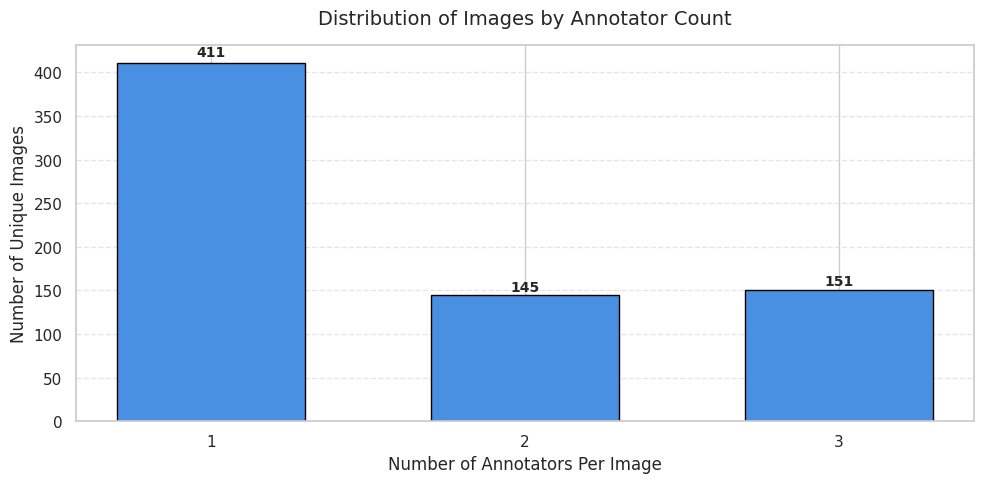

In [5]:
# Map filenames to their corresponding duplicate image ids
name_to_image_ids = defaultdict(list)
for image in annotations["images"]:
    name_to_image_ids[image["file_name"]].append(image["id"])

image_annotator_counts = {
    file_name: len(ids) for file_name, ids in name_to_image_ids.items()
}

distribution = Counter(image_annotator_counts.values())

# Plot 1: Image Count vs. Annotator Count
annotator_counts = sorted(distribution.keys())
image_counts = [distribution[c] for c in annotator_counts]

plt.figure(figsize=(10, 5))
bars = plt.bar(
    annotator_counts, image_counts, color="#4A90E2", edgecolor="black", width=0.6
)

plt.title("Distribution of Images by Annotator Count", fontsize=14, pad=15)
plt.xlabel("Number of Annotators Per Image", fontsize=12)
plt.ylabel("Number of Unique Images", fontsize=12)
plt.xticks(annotator_counts)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (yval * 0.01),
        f"{int(yval)}",
        ha="center",
        va="bottom",
        fontsize=10,
        weight="bold",
    )

plt.tight_layout()
plt.show()

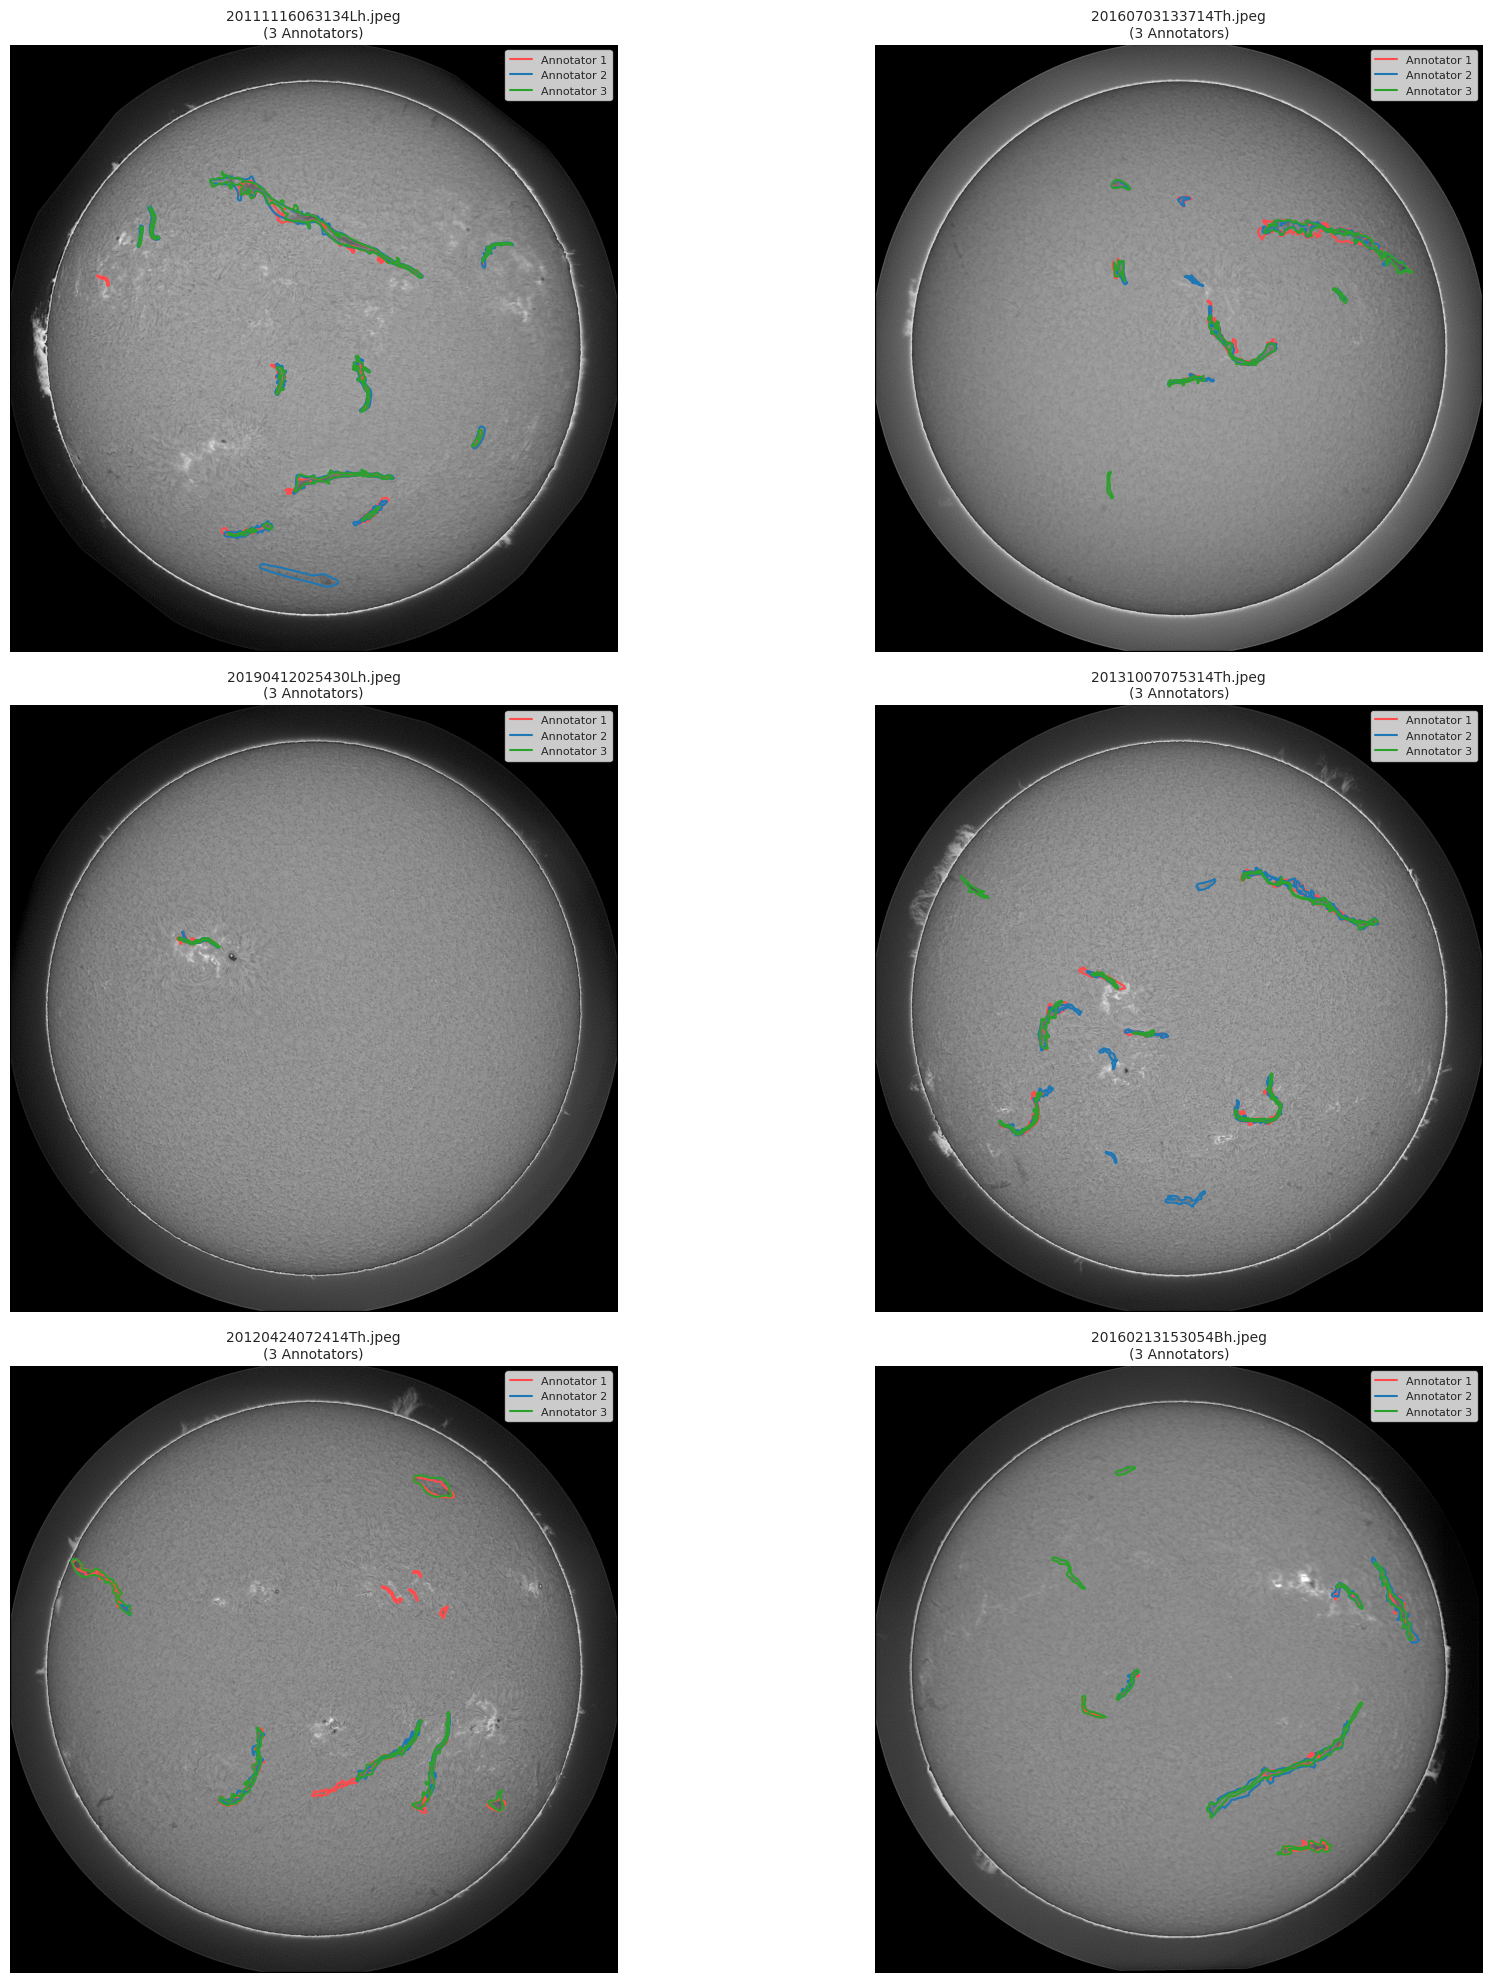

In [6]:
# Plot Example images with multiple annotators
sorted_images = sorted(
    name_to_image_ids.items(), key=lambda item: len(item[1]), reverse=True
)
examples = sorted_images[:6]
colors = ["#FF4B4B", "#1F77B4", "#2CA02C"]

fig, axes = plt.subplots(3, 2, figsize=(20, 20))
axes = axes.flatten()

for i, (file_name, ids) in enumerate(examples):
    ax = axes[i]

    # Load and display the image
    img_path = f"{TRAIN_IMAGES_DIR}/{file_name}"
    image = np.array(Image.open(img_path).convert("L"))
    ax.imshow(image, cmap="gray")
    legend_labels = []

    for idx, img_id in enumerate(ids):
        anns = [a for a in annotations["annotations"] if a["image_id"] == img_id]
        color = colors[idx % len(colors)]

        # Plot each polygon for this specific annotator
        for ann in anns:
            for poly in ann["segmentation"]:
                xs = poly[0::2]
                ys = poly[1::2]
                ax.plot(xs + [xs[0]], ys + [ys[0]], color=color, linewidth=1.5)

        # Add to legend tracker if annotations exist
        if anns:
            legend_labels.append(
                plt.Line2D([0], [0], color=color, lw=1.5, label=f"Annotator {idx+1}")
            )

    # Set title, legend, and clean up axes
    ax.set_title(f"{file_name}\n({len(ids)} Annotators)", fontsize=10)
    ax.axis("off")
    if legend_labels:
        ax.legend(handles=legend_labels, loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# Check out Example Polygon Mask


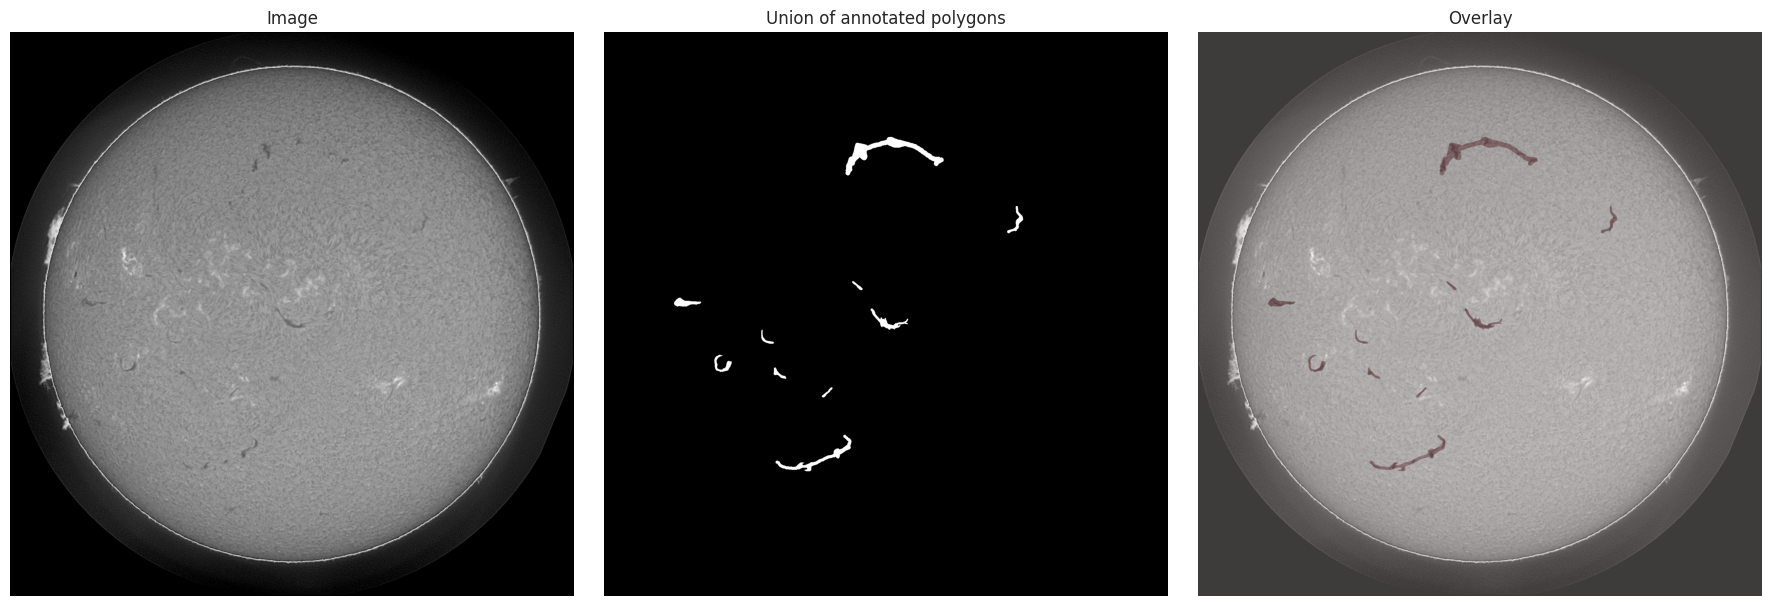

In [7]:
def polygons_to_mask(image_id, data):
    img_info = next(img for img in data["images"] if img["id"] == image_id)
    height, width = img_info["height"], img_info["width"]
    mask = np.zeros((height, width), dtype=np.uint8)
    anns = [ann for ann in data["annotations"] if ann["image_id"] == image_id]
    for ann in anns:
        for polygon in ann["segmentation"]:
            points = np.asarray(polygon, dtype=np.float32).reshape((-1, 2))
            if len(points) >= 3:
                cv2.fillPoly(mask, [np.round(points).astype(np.int32)], color=1)
    return mask, img_info


def plot_image_mask_overlay(image, mask, img_info, images_dir):
    image_path = Path(images_dir) / img_info["file_name"]
    image = np.asarray(Image.open(image_path).convert("L"))
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Image")
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Union of annotated polygons")
    axes[2].imshow(image, cmap="gray")
    axes[2].imshow(mask, cmap="Reds", alpha=0.25)
    axes[2].set_title("Overlay")
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()


sample_index = min(200, len(annotations["images"]) - 1)
image_rnd_id = annotations["images"][sample_index]["id"]
mask, info = polygons_to_mask(image_id=image_rnd_id, data=annotations)
plot_image_mask_overlay(
    image=None, mask=mask, img_info=info, images_dir=TRAIN_IMAGES_DIR
)

# Pre-processing and Data Augmentation


## Split the data into train and validation sets

Images with multiple annotators stay in training. Validation uses only single-annotator images. The split is measured over unique source files so one photograph cannot appear on both sides.


In [8]:
SPLIT_RATIO = 0.2
RANDOM_SEED = 10


def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Tiles have one fixed shape, so cuDNN can safely retain its fastest kernel choice.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


seed_everything(RANDOM_SEED)
print(f"Global seed set to {RANDOM_SEED}")
image_ids = [img["id"] for img in annotations["images"]]
image_annotator_counts = {
    img["id"]: len(name_to_image_ids[img["file_name"]]) for img in annotations["images"]
}
single_annotator_ids = [i for i in image_ids if image_annotator_counts[i] == 1]
multi_annotator_ids = [i for i in image_ids if image_annotator_counts[i] > 1]

val_target_size = max(1, round(len(name_to_image_ids) * SPLIT_RATIO))
if len(single_annotator_ids) < 2:
    raise ValueError("Need at least two single-annotator records for validation.")
val_target_size = min(val_target_size, len(single_annotator_ids) - 1)
train_single_ids, val_image_ids = train_test_split(
    single_annotator_ids,
    test_size=val_target_size,
    random_state=RANDOM_SEED,
    shuffle=True,
)
train_image_ids = train_single_ids + multi_annotator_ids
file_by_id = {img["id"]: img["file_name"] for img in annotations["images"]}
train_files = {file_by_id[i] for i in train_image_ids}
val_files = {file_by_id[i] for i in val_image_ids}
if train_files & val_files:
    raise RuntimeError("Data leakage detected: a source file occurs in both splits.")

print(f"Unique source files: {len(name_to_image_ids):,}")
print(
    f"Training annotation records: {len(train_image_ids):,}; source files: {len(train_files):,}"
)
print(
    f"Validation annotation records: {len(val_image_ids):,}; source files: {len(val_files):,}"
)
print(f"Multi-annotator records kept in training: {len(multi_annotator_ids):,}")

Global seed set to 10
Unique source files: 707
Training annotation records: 1,013; source files: 566
Validation annotation records: 141; source files: 141
Multi-annotator records kept in training: 743


## Build Data-set

- Tile images from 2048x2048 to 512x512 for training and validation.


In [9]:
def tile_image_and_mask(image_id, data, image_dir, split_name):
    mask, img_info = polygons_to_mask(image_id, data)
    image_path = Path(image_dir) / img_info["file_name"]
    image = np.asarray(Image.open(image_path).convert("L"))
    height, width = mask.shape
    if image.shape != mask.shape:
        raise ValueError(f"Image/mask dimensions differ for {img_info['file_name']}")
    if height % TILE_SIZE or width % TILE_SIZE:
        raise ValueError(f"Image dimensions must be divisible by TILE_SIZE={TILE_SIZE}")

    tiles = []
    for row in range(height // TILE_SIZE):
        for col in range(width // TILE_SIZE):
            y0, x0 = row * TILE_SIZE, col * TILE_SIZE
            image_tile = image[y0 : y0 + TILE_SIZE, x0 : x0 + TILE_SIZE]
            mask_tile = mask[y0 : y0 + TILE_SIZE, x0 : x0 + TILE_SIZE]
            positive_pixels = int(mask_tile.sum())
            tiles.append(
                {
                    "source_image_id": image_id,
                    "source_file_name": img_info["file_name"],
                    "row": row,
                    "col": col,
                    "split": split_name,
                    "tile_name": f"{image_id}_r{row}_c{col}.png",
                    "has_filament": positive_pixels > 0,
                    "positive_pixels": positive_pixels,
                    "image_tile": image_tile,
                    "mask_tile": mask_tile,
                    "orig_height": height,
                    "orig_width": width,
                }
            )
    return tiles


def reconstruct_from_tiles(tiles, tile_type="mask_tile", tile_size=TILE_SIZE):
    if not tiles:
        raise ValueError("The tiles list is empty.")
    height, width = int(tiles[0]["orig_height"]), int(tiles[0]["orig_width"])
    canvas = np.zeros((height, width), dtype=tiles[0][tile_type].dtype)
    for tile in tiles:
        y0, x0 = int(tile["row"]) * tile_size, int(tile["col"]) * tile_size
        canvas[y0 : y0 + tile_size, x0 : x0 + tile_size] = tile[tile_type]
    return canvas

### Validate the tiling process by visualizing a few tiles and their corresponding masks.


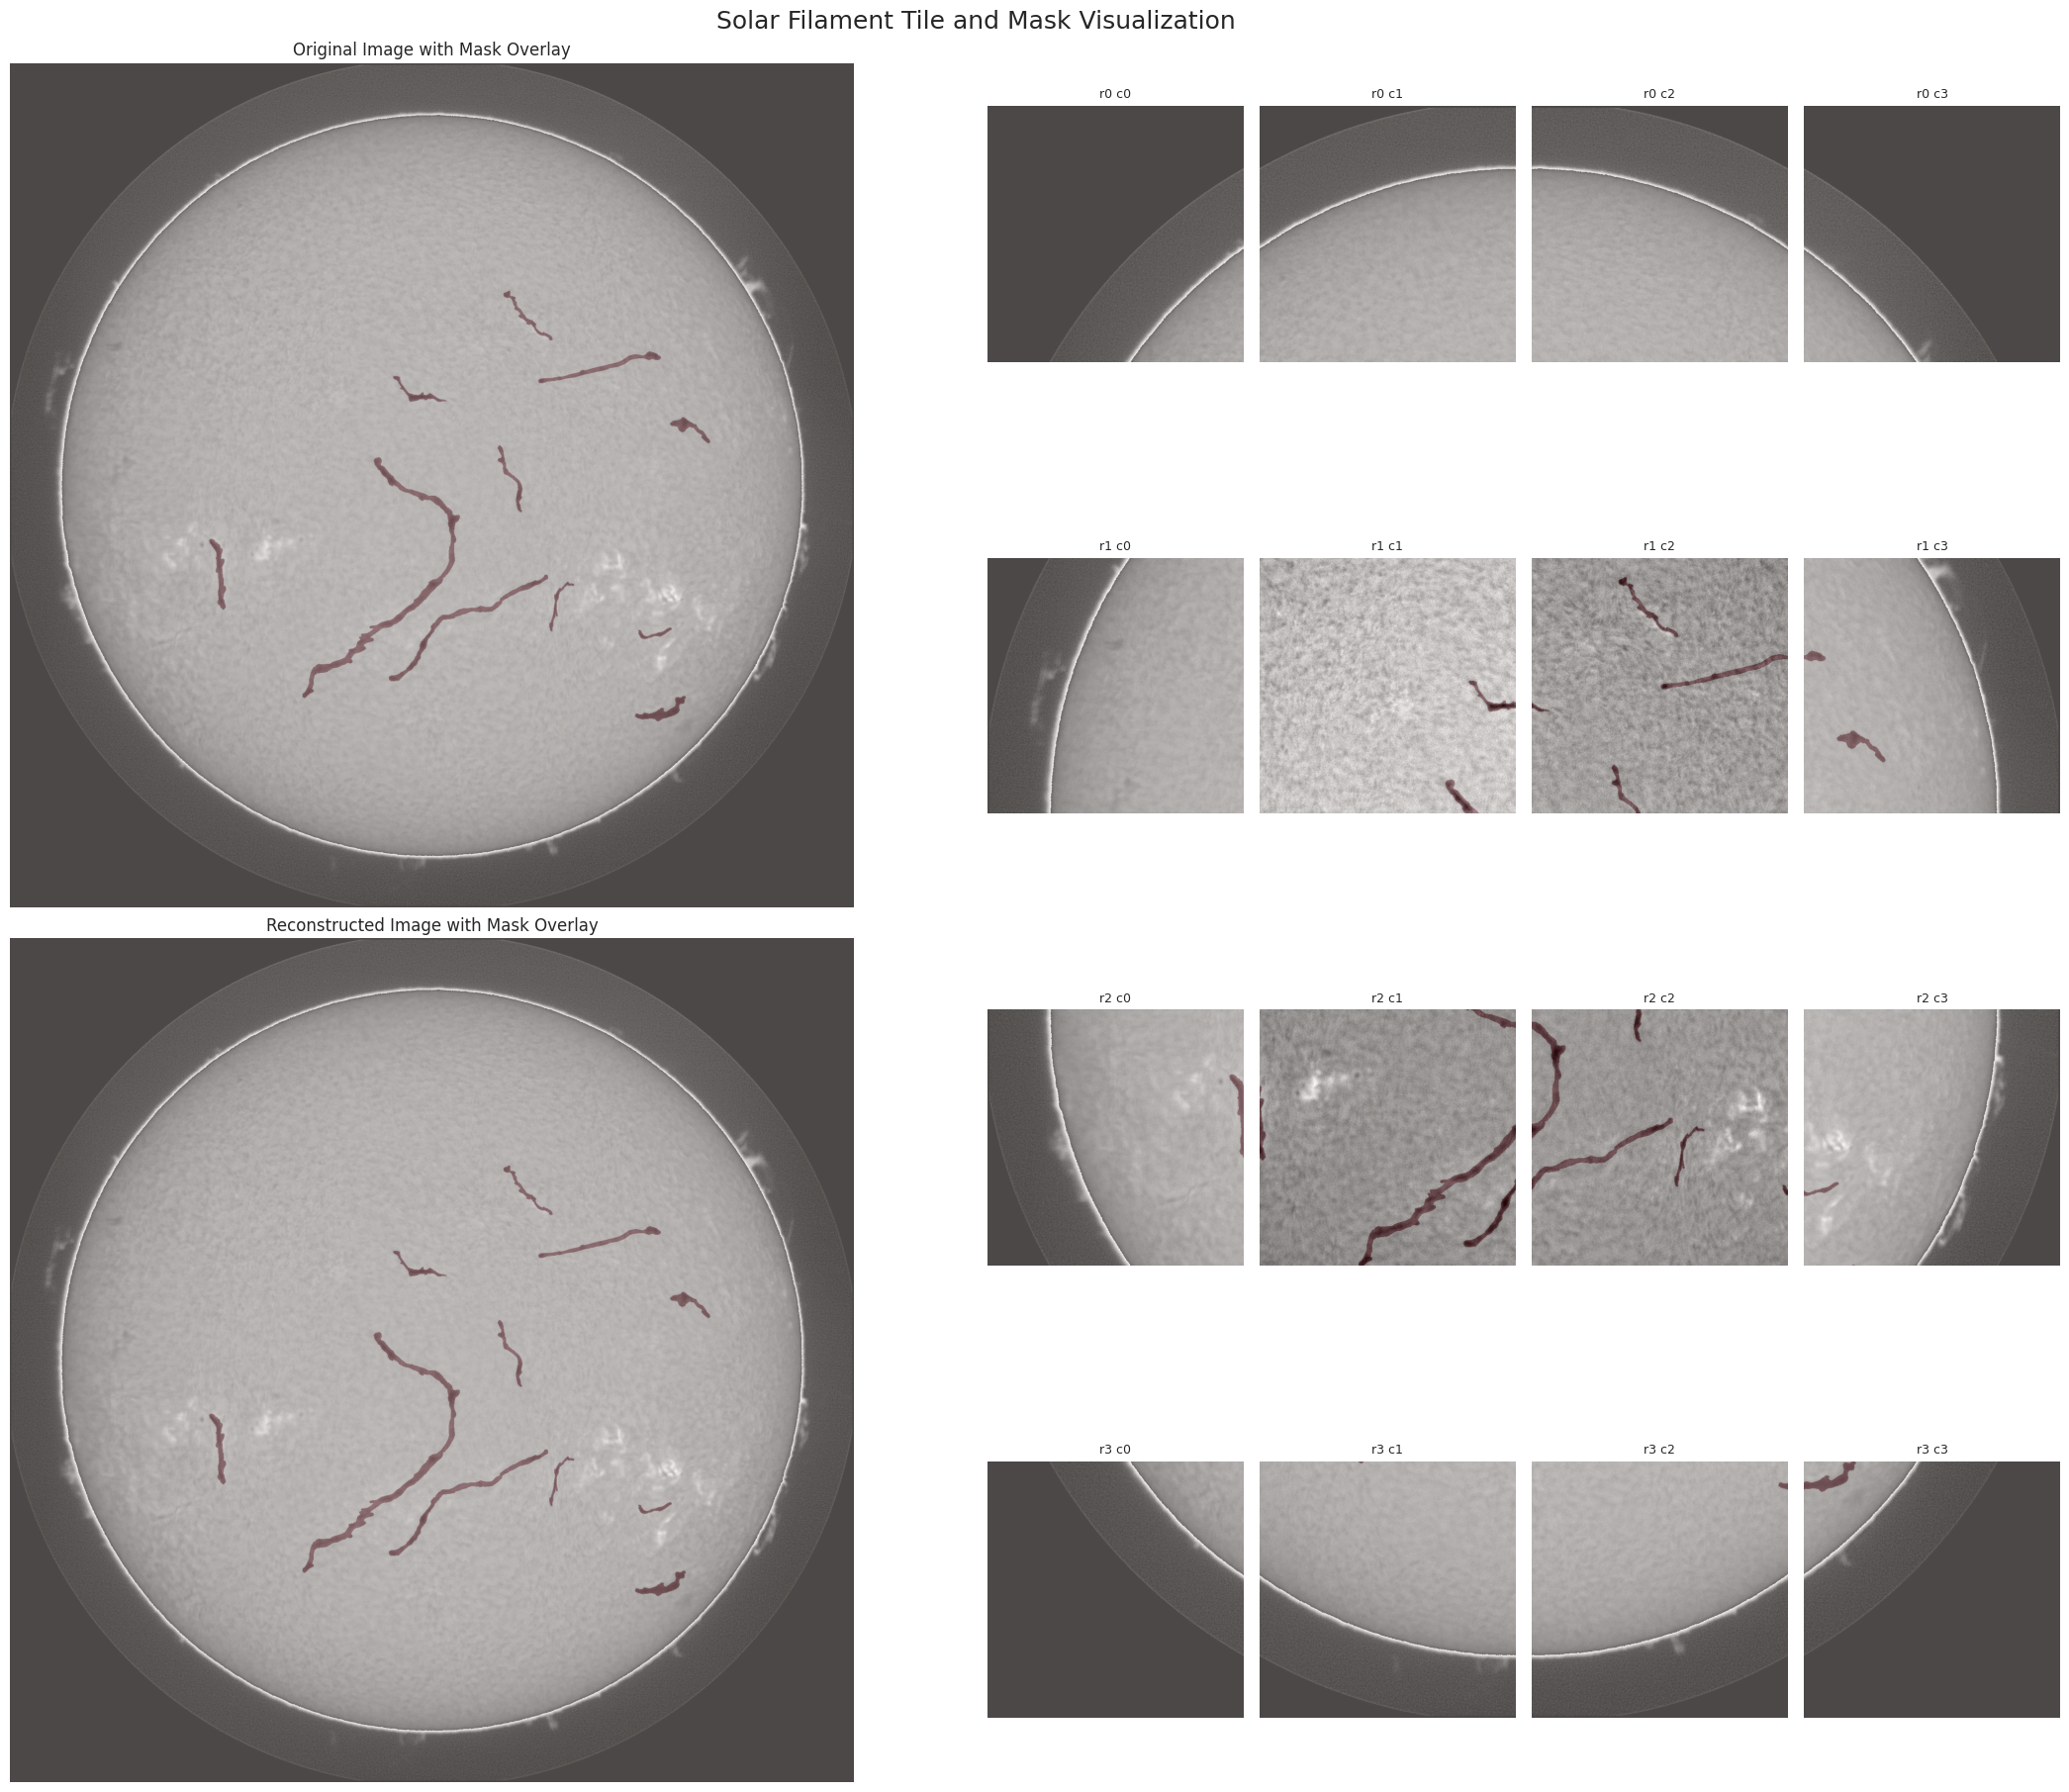

In [10]:
# 1. Tile a specific validation image into 16 patches
validation_visual_id = val_image_ids[0]
validation_tiles = tile_image_and_mask(
    image_id=validation_visual_id,
    data=annotations,
    image_dir=TRAIN_IMAGES_DIR,
    split_name="val",
)

# 2. Reconstruct the full layout
full_reconstructed_mask = reconstruct_from_tiles(
    validation_tiles, tile_type="mask_tile"
)

# Visualize the original image, 16 tiles, and reconstructed image with mask overlays
original_info = next(
    img for img in annotations["images"] if img["id"] == validation_visual_id
)
original_path = TRAIN_IMAGES_DIR / original_info["file_name"]
original_image = np.array(Image.open(original_path).convert("L"))
original_mask, _ = polygons_to_mask(validation_visual_id, annotations)
reconstructed_image = reconstruct_from_tiles(validation_tiles, tile_type="image_tile")
reconstructed_mask = reconstruct_from_tiles(validation_tiles, tile_type="mask_tile")

fig = plt.figure(figsize=(22, 18), constrained_layout=True)
grid = fig.add_gridspec(4, 2, width_ratios=[1, 1], height_ratios=[1, 1, 1, 1])

# Original image with overlay
ax_original = fig.add_subplot(grid[:2, 0])
ax_original.imshow(original_image, cmap="gray")
ax_original.imshow(original_mask, cmap="Reds", alpha=0.3)
ax_original.set_title("Original Image with Mask Overlay")
ax_original.axis("off")

# Reconstructed image with overlay
ax_reconstructed = fig.add_subplot(grid[2:, 0])
ax_reconstructed.imshow(reconstructed_image, cmap="gray")
ax_reconstructed.imshow(reconstructed_mask, cmap="Reds", alpha=0.3)
ax_reconstructed.set_title("Reconstructed Image with Mask Overlay")
ax_reconstructed.axis("off")

# Sixteen tiles in their spatial 4x4 arrangement
subgrid = grid[:, 1].subgridspec(4, 4, wspace=0.03, hspace=0.15)
for tile in validation_tiles:
    ax = fig.add_subplot(subgrid[tile["row"], tile["col"]])
    ax.imshow(tile["image_tile"], cmap="gray")
    ax.imshow(tile["mask_tile"], cmap="Reds", alpha=0.3)
    ax.set_title(f"r{tile['row']} c{tile['col']}", fontsize=9)
    ax.axis("off")

fig.suptitle("Solar Filament Tile and Mask Visualization", fontsize=18)
plt.show()

### Create Tiles and Masks for Training and Validation


In [11]:
from concurrent.futures import ThreadPoolExecutor

TILED_DATASET_DIR = Path.cwd() / "solar_filament_tiles"
NUM_WORKERS = min(8, os.cpu_count() or 4)

for split_name in ("train", "val"):
    for folder in ("images", "masks"):
        (TILED_DATASET_DIR / split_name / folder).mkdir(parents=True, exist_ok=True)


def process_image(image_id, split_name):
    tiles = tile_image_and_mask(
        image_id=image_id,
        data=annotations,
        image_dir=TRAIN_IMAGES_DIR,
        split_name=split_name,
    )
    records = []
    for tile in tiles:
        image_out = TILED_DATASET_DIR / split_name / "images" / tile["tile_name"]
        mask_out = TILED_DATASET_DIR / split_name / "masks" / tile["tile_name"]

        Image.fromarray(tile["image_tile"].astype(np.uint8)).save(image_out)
        mask_data = (tile["mask_tile"] > 0).astype(np.uint8) * 255
        Image.fromarray(mask_data).save(mask_out)

        records.append(
            {
                key: value
                for key, value in tile.items()
                if key not in {"image_tile", "mask_tile"}
            }
        )

    return records


all_tile_records = []

for split_name, split_image_ids in (("train", train_image_ids), ("val", val_image_ids)):
    split_records = []

    with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
        futures = [
            executor.submit(process_image, image_id, split_name)
            for image_id in split_image_ids
        ]

        for index, future in enumerate(futures, start=1):
            split_records.extend(future.result())

            if index % 50 == 0 or index == len(futures):
                print(f"{split_name}: processed {index:,}/" f"{len(futures):,} images")

    pd.DataFrame(split_records).to_csv(
        TILED_DATASET_DIR / split_name / "metadata.csv",
        index=False,
    )

    all_tile_records.extend(split_records)
    print(f"{split_name}: {len(split_records):,} tiles written")


pd.DataFrame(all_tile_records).to_csv(
    TILED_DATASET_DIR / "metadata.csv",
    index=False,
)

with open(TILED_DATASET_DIR / "dataset_info.json", "w") as f:
    json.dump(
        {
            "tile_size": 512,
            "image_mode": "L",
            "mask_values": {"background": 0, "filament": 255},
            "train_images": len(train_image_ids),
            "validation_images": len(val_image_ids),
            "train_tiles": sum(row["split"] == "train" for row in all_tile_records),
            "validation_tiles": sum(row["split"] == "val" for row in all_tile_records),
        },
        f,
        indent=2,
    )

print(f"Tiled dataset saved to: {TILED_DATASET_DIR}")

train: processed 50/1,013 images
train: processed 100/1,013 images
train: processed 150/1,013 images
train: processed 200/1,013 images
train: processed 250/1,013 images
train: processed 300/1,013 images
train: processed 350/1,013 images
train: processed 400/1,013 images
train: processed 450/1,013 images
train: processed 500/1,013 images
train: processed 550/1,013 images
train: processed 600/1,013 images
train: processed 650/1,013 images
train: processed 700/1,013 images
train: processed 750/1,013 images
train: processed 800/1,013 images
train: processed 850/1,013 images
train: processed 900/1,013 images
train: processed 950/1,013 images
train: processed 1,000/1,013 images
train: processed 1,013/1,013 images
train: 16,208 tiles written
val: processed 50/141 images
val: processed 100/141 images
val: processed 141/141 images
val: 2,256 tiles written
Tiled dataset saved to: /kaggle/working/solar_filament_tiles


## Custom PyTorch U-Net

The network is implemented here with an encoder, bottleneck, skip connections, and decoder. It learns a binary union mask from polygon annotations. Training keeps positive tiles and samples a configurable number of empty tiles to reduce background-only work.


In [12]:
# Kaggle throughput settings: two 15 GiB T4s and four CPU loader workers.
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA became unavailable. Stop and restart this notebook with a GPU accelerator enabled."
    )

DEVICE = torch.device("cuda:0")
torch.cuda.set_device(DEVICE)
NUM_GPUS = torch.cuda.device_count()
GPU_IDS = list(range(NUM_GPUS))
GPU_NAMES = [torch.cuda.get_device_name(index) for index in GPU_IDS]
GPU_MEMORY_GIB = [
    torch.cuda.get_device_properties(index).total_memory / (1024**3)
    for index in GPU_IDS
]
if not NUM_GPUS:
    raise RuntimeError("No CUDA devices were found.")

# Kaggle measurements: 16/GPU reached about 66 tiles/s; 32/GPU reached about 60.
# Keep the faster measured batch; higher VRAM use did not improve throughput.
PER_GPU_BATCH_SIZE = 32
BATCH_SIZE = PER_GPU_BATCH_SIZE * NUM_GPUS
NUM_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
# Balance the binary-union PQ surrogate, foreground overlap, and pixel calibration.
LOSS_WEIGHTS = {"log_soft_pq": 0.4, "dice": 0.4, "bce": 0.2}
BASE_CHANNELS = 32
# One balanced background tile per positive tile cuts wasted background-only batches.
NEGATIVE_TO_POSITIVE_TILE_RATIO = 1

CPU_COUNT = os.cpu_count() or 1
IS_LINUX = sys.platform.startswith("linux")
NUM_WORKERS = min(4, CPU_COUNT) if IS_LINUX else 0
PREFETCH_FACTOR = 4
AMP_ENABLED = True
# Choose the fastest layout on the actual Kaggle GPUs, not from local GPU timings.
AUTOTUNE_LAYOUT = True
USE_CHANNELS_LAST = False
# Use predictable heuristic kernels; avoid a long cuDNN exhaustive search.
CUDNN_BENCHMARK = False
LOG_EVERY_STEPS = 20
# Profile real steps after warmup only in epoch 1; later epochs avoid forced CPU/GPU sync.
# DDP still synchronizes gradients and global Dice statistics each training batch.
PROFILE_FIRST_TRAINING_EPOCH = True
BENCHMARK_WARMUP_STEPS = 3
BENCHMARK_STEPS = 8
TRACK_TRAIN_DICE = False

# Pack uint8 tiles once. Read-only mmap files share OS cache pages across both
# training processes and four loader workers; there is no full cache copy per rank.
CACHE_TILES_REQUESTED = True
CACHE_RESERVED_GIB = 8.0
CPU_POSTPROCESS_WORKERS = NUM_WORKERS
MAX_PENDING_POSTPROCESS = CPU_POSTPROCESS_WORKERS * 2
cv2.setNumThreads(1)
torch.set_num_threads(1)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = CUDNN_BENCHMARK
if hasattr(torch, "set_float32_matmul_precision"):
    torch.set_float32_matmul_precision("high")

TILED_DATASET_DIR = Path.cwd() / "solar_filament_tiles"
OUTPUT_DIR = Path.cwd() / "unet_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "custom_unet_best.pth"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
SUBMISSION_PATH = Path.cwd() / "solar_filament_unet_submission.csv"

train_metadata_path = TILED_DATASET_DIR / "train" / "metadata.csv"
val_metadata_path = TILED_DATASET_DIR / "val" / "metadata.csv"
for required_path in (train_metadata_path, val_metadata_path):
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Missing tiled metadata: {required_path}. Run the tile creation cell first."
        )

train_metadata = pd.read_csv(train_metadata_path)
val_metadata = pd.read_csv(val_metadata_path)
is_positive = train_metadata["has_filament"].astype(str).str.lower().eq("true")
train_positive = train_metadata[is_positive]
train_negative = train_metadata[~is_positive]
if train_positive.empty:
    raise ValueError("No filament-positive training tiles were created.")
negative_limit = min(
    len(train_negative), len(train_positive) * NEGATIVE_TO_POSITIVE_TILE_RATIO
)
if negative_limit:
    train_negative = train_negative.sample(n=negative_limit, random_state=RANDOM_SEED)
train_metadata = pd.concat([train_positive, train_negative], ignore_index=True)
train_metadata = train_metadata.sample(frac=1, random_state=RANDOM_SEED).reset_index(
    drop=True
)

def available_ram_gib():
    try:
        page_size = os.sysconf("SC_PAGE_SIZE")
        available_pages = os.sysconf("SC_AVPHYS_PAGES")
        return page_size * available_pages / (1024**3)
    except (AttributeError, OSError, ValueError):
        return None


cache_bytes = (len(train_metadata) + len(val_metadata)) * 2 * TILE_SIZE * TILE_SIZE
estimated_cache_gib = cache_bytes / (1024**3)
available_memory_gib = available_ram_gib()
CACHE_TILES_PACKED = (
    CACHE_TILES_REQUESTED
    and IS_LINUX
    and available_memory_gib is not None
    and available_memory_gib >= estimated_cache_gib + CACHE_RESERVED_GIB
)

print(f"GPUs ({NUM_GPUS}): {list(zip(GPU_NAMES, [round(x, 1) for x in GPU_MEMORY_GIB]))}")
print(
    f"Global batch: {BATCH_SIZE} ({PER_GPU_BATCH_SIZE} per GPU); AMP: {AMP_ENABLED}; "
    f"loader workers: {NUM_WORKERS}; prefetch factor: {PREFETCH_FACTOR}"
)
print(
    f"Training tiles: {len(train_metadata):,} (positive {len(train_positive):,}, "
    f"sampled negative {len(train_negative):,}); validation tiles: {len(val_metadata):,}"
)
ram_text = "unavailable" if available_memory_gib is None else f"{available_memory_gib:.1f} GiB free"
print(
    f"Shared packed tile cache: {CACHE_TILES_PACKED} ({estimated_cache_gib:.1f} GiB estimate; {ram_text})"
)
print(f"Checkpoint: {CHECKPOINT_PATH}")

GPUs (2): [('Tesla T4', 14.6), ('Tesla T4', 14.6)]
Global batch: 64 (32 per GPU); AMP: True; loader workers: 4; prefetch factor: 4
Training tiles: 11,760 (positive 5,880, sampled negative 5,880); validation tiles: 2,256
Shared packed tile cache: True (6.8 GiB estimate; 19.5 GiB free)
Checkpoint: /kaggle/working/unet_outputs/custom_unet_best.pth


## Train and select the checkpoint

The earlier logs show a lower validation PQ **loss**, not a measurement of higher Panoptic Quality. Exact PQ uses thresholded instances and discrete IoU matching, so it is not differentiable. These labels and model outputs are binary union masks; the existing log-soft-PQ loss is an overlap surrogate and can improve while thresholded pixel Dice falls.

Training now minimizes `0.4 * log_soft_PQ_loss + 0.4 * (1 - global_soft_Dice) + 0.2 * BCEWithLogits`. The first term retains the binary-union PQ surrogate, the second directly rewards foreground overlap, and the unweighted BCE term penalizes pixel errors and helps calibrate probabilities. All loss calculations use float32 even when the model uses mixed precision. The Dice training term uses the global batch synchronized across GPU processes; validation soft Dice is computed from totals over the full validation dataset. `LOSS_WEIGHTS` exposes the balance for later experiments.

Checkpoint selection, the learning-rate scheduler, and early stopping use the same weighted validation objective with **hard pixel Dice at 0.5** replacing soft Dice: `0.4 * validation_log_soft_PQ_loss + 0.4 * (1 - validation_Dice_at_0.5) + 0.2 * validation_BCE`. This makes deterioration in the reported Dice count against a checkpoint; it does not guarantee both metrics improve at every epoch. The history records the total loss, each loss component, soft Dice, hard Dice, and the validation selection loss separately. A final threshold sweep balances measured component-PQ and pixel Dice using their harmonic mean.

The next cell exports its embedded worker and automatically launches one persistent training process per GPU with DistributedDataParallel. Four total loader workers read a shared packed grayscale tile cache. The worker measures both tensor layouts on the Kaggle GPUs and prints its profile early in the first epoch, plus regular progress. The checkpoint is reloaded into the notebook for threshold selection and submission. No separate Python upload is needed.


In [13]:
# Export the embedded worker, then launch one persistent process per GPU.
# This notebook is self-contained: no separately uploaded Python file is needed.
import importlib.util
import subprocess

UNET_RUNTIME_SOURCE = '"""Self-contained U-Net worker embedded in solar-filament-u-net.ipynb for Kaggle."""\nimport argparse\nimport csv\nimport gc\nimport hashlib\nimport json\nimport os\nimport random\nimport shutil\nimport sys\nimport time\nfrom datetime import timedelta\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\nimport torch\nimport torch.distributed as dist\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom torch.nn.parallel import DistributedDataParallel\nfrom torch.utils.data import DataLoader, Dataset, DistributedSampler\n\n\nclass DoubleConv(nn.Module):\n    def __init__(self, in_channels, out_channels):\n        super().__init__()\n        self.layers = nn.Sequential(\n            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),\n            nn.BatchNorm2d(out_channels),\n            nn.ReLU(inplace=True),\n            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),\n            nn.BatchNorm2d(out_channels),\n            nn.ReLU(inplace=True),\n        )\n\n    def forward(self, x):\n        return self.layers(x)\n\n\nclass CustomUNet(nn.Module):\n    def __init__(self, in_channels=1, out_channels=1, base_channels=32):\n        super().__init__()\n        c = base_channels\n        self.enc1 = DoubleConv(in_channels, c)\n        self.enc2 = DoubleConv(c, c * 2)\n        self.enc3 = DoubleConv(c * 2, c * 4)\n        self.enc4 = DoubleConv(c * 4, c * 8)\n        self.bottleneck = DoubleConv(c * 8, c * 16)\n        self.pool = nn.MaxPool2d(2, 2)\n        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, 2, 2)\n        self.dec4 = DoubleConv(c * 16, c * 8)\n        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, 2, 2)\n        self.dec3 = DoubleConv(c * 8, c * 4)\n        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, 2, 2)\n        self.dec2 = DoubleConv(c * 4, c * 2)\n        self.up1 = nn.ConvTranspose2d(c * 2, c, 2, 2)\n        self.dec1 = DoubleConv(c * 2, c)\n        self.output = nn.Conv2d(c, out_channels, 1)\n\n    def forward(self, x):\n        s1 = self.enc1(x)\n        s2 = self.enc2(self.pool(s1))\n        s3 = self.enc3(self.pool(s2))\n        s4 = self.enc4(self.pool(s3))\n        x = self.bottleneck(self.pool(s4))\n        x = self.dec4(torch.cat([self.up4(x), s4], dim=1))\n        x = self.dec3(torch.cat([self.up3(x), s3], dim=1))\n        x = self.dec2(torch.cat([self.up2(x), s2], dim=1))\n        x = self.dec1(torch.cat([self.up1(x), s1], dim=1))\n        return self.output(x)\n\n\nDEFAULT_LOSS_WEIGHTS = {\'log_soft_pq\': 0.4, \'dice\': 0.4, \'bce\': 0.2}\n\n\ndef validate_loss_weights(weights):\n    if set(weights) != set(DEFAULT_LOSS_WEIGHTS):\n        raise ValueError(f\'loss_weights must contain exactly {tuple(DEFAULT_LOSS_WEIGHTS)}\')\n    weights = {name: float(value) for name, value in weights.items()}\n    if any(not np.isfinite(value) or value < 0 for value in weights.values()):\n        raise ValueError(\'Loss weights must be finite and nonnegative.\')\n    if not np.isclose(sum(weights.values()), 1.0):\n        raise ValueError(\'Loss weights must sum to 1.\')\n    return weights\n\n\ndef segmentation_loss(logits, targets, weights=None, sync_dice=False, smooth=1.0):\n    """Combine the union-PQ surrogate, global foreground Dice, and pixel BCE.\n\n    sync_dice pools sufficient statistics over all training ranks. The straight-\n    through gradient is scaled by world size to compensate DDP\'s gradient mean.\n    Validation must leave it off: ranks can have unequal numbers of batches.\n    """\n    weights = DEFAULT_LOSS_WEIGHTS if weights is None else weights\n    with torch.autocast(device_type=logits.device.type, enabled=False):\n        logits = logits.float()\n        probabilities = logits.sigmoid()\n        targets = targets.float()\n        dims = (1, 2, 3)\n        intersection = (probabilities * targets).sum(dim=dims)\n        predicted_area = probabilities.sum(dim=dims)\n        target_area = targets.sum(dim=dims)\n        total_area = predicted_area + target_area\n        soft_sq = (intersection + smooth) / (total_area - intersection + smooth)\n        soft_rq = (2.0 * intersection + smooth) / (total_area + smooth)\n        positive_loss = -0.5 * (\n            soft_sq.clamp_min(1e-6).log() + soft_rq.clamp_min(1e-6).log()\n        )\n        empty_loss = predicted_area / float(targets.shape[-2] * targets.shape[-1])\n        pq_loss = torch.where(target_area > 0, positive_loss, empty_loss).mean()\n        # Reuse the overlap reductions; Dice pools pixels rather than averaging tiles.\n        overlap = torch.stack((intersection.sum(), predicted_area.sum(), target_area.sum()))\n        dice_overlap = overlap\n        if sync_dice:\n            global_overlap = overlap.detach().clone()\n            dist.all_reduce(global_overlap)\n            dice_overlap = global_overlap + dist.get_world_size() * (overlap - overlap.detach())\n        soft_dice = (2.0 * dice_overlap[0] + smooth) / (\n            dice_overlap[1] + dice_overlap[2] + smooth\n        )\n        # Unweighted BCE encourages calibration without reweighting class costs.\n        # It also corrects confident mistakes when sigmoid-overlap gradients saturate.\n        bce_loss = F.binary_cross_entropy_with_logits(logits, targets)\n        loss = (\n            weights[\'log_soft_pq\'] * pq_loss\n            + weights[\'dice\'] * (1.0 - soft_dice)\n            + weights[\'bce\'] * bce_loss\n        )\n        return dict(loss=loss, log_soft_pq_loss=pq_loss, soft_dice=soft_dice,\n                    bce_loss=bce_loss, overlap=overlap)\n\n\ndef log_soft_panoptic_quality_loss(logits, targets, smooth=1.0):\n    """Retain the original surrogate as a separately logged diagnostic."""\n    return segmentation_loss(logits, targets, smooth=smooth)[\'log_soft_pq_loss\']\n\n\ndef summarize_epoch_totals(totals, weights, training):\n    """Reduce validation Dice once over the complete, non-padding dataset."""\n    samples = totals[\'samples\']\n    if samples == 0:\n        raise ValueError(\'Empty epoch. Reduce the per-GPU batch or check metadata.\')\n    pq_loss = totals[\'log_soft_pq_loss\'] / samples\n    bce_loss = totals[\'bce_loss\'] / samples\n    if training:\n        soft_dice = totals[\'soft_dice\'] / samples\n        hard_dice = float(\'nan\')\n        loss = totals[\'loss\'] / samples\n        selection_loss = float(\'nan\')\n    else:\n        soft_dice = (2.0 * totals[\'soft_intersection\'] + 1.0) / (\n            totals[\'predicted_area\'] + totals[\'target_area\'] + 1.0\n        )\n        hard_dice = (2.0 * totals[\'hard_intersection\'] + 1.0) / (\n            totals[\'hard_denominator\'] + 1.0\n        )\n        loss = (weights[\'log_soft_pq\'] * pq_loss + weights[\'dice\'] * (1.0 - soft_dice)\n                + weights[\'bce\'] * bce_loss)\n        # Select against the same hard threshold shown in the epoch logs.\n        selection_loss = (weights[\'log_soft_pq\'] * pq_loss + weights[\'dice\'] * (1.0 - hard_dice)\n                          + weights[\'bce\'] * bce_loss)\n    return dict(loss=loss, log_soft_pq_loss=pq_loss, soft_dice=soft_dice,\n                bce_loss=bce_loss, dice_at_0_5=hard_dice, selection_loss=selection_loss)\n\n\nclass FilamentTileDataset(Dataset):\n    def __init__(self, manifest, augment=False):\n        self.manifest = manifest\n        self.tile_names = manifest[\'tile_names\']\n        self.augment = augment\n        self.packed = None\n\n    def __len__(self):\n        return len(self.tile_names)\n\n    def __getitem__(self, index):\n        packed_path = self.manifest.get(\'packed_path\')\n        if packed_path:\n            if self.packed is None:\n                self.packed = np.load(packed_path, mmap_mode=\'r\')\n            image, mask = self.packed[index]\n        else:\n            root = Path(self.manifest[\'split_dir\'])\n            name = self.tile_names[index]\n            image = cv2.imread(str(root / \'images\' / name), cv2.IMREAD_GRAYSCALE)\n            mask = cv2.imread(str(root / \'masks\' / name), cv2.IMREAD_GRAYSCALE)\n            if image is None or mask is None:\n                raise OSError(f\'Unreadable tile pair: {root / name}\')\n            mask = (mask > 127).astype(np.uint8)\n        if self.augment:\n            if random.random() < 0.5:\n                image, mask = np.fliplr(image), np.fliplr(mask)\n            if random.random() < 0.5:\n                image, mask = np.flipud(image), np.flipud(mask)\n            turns = random.randrange(4)\n            if turns:\n                image, mask = np.rot90(image, turns), np.rot90(mask, turns)\n        # Copy read-only mmap views before exposing them as writable Torch tensors.\n        image = np.array(image[None], dtype=np.uint8, order=\'C\', copy=True)\n        mask = np.array(mask[None], dtype=np.uint8, order=\'C\', copy=True)\n        return torch.from_numpy(image), torch.from_numpy(mask)\n\n\ndef build_tile_manifest(metadata, split_dir, cache_dir, tile_size, use_cache=True):\n    """Pack once; all GPU processes and workers share OS-backed read-only pages."""\n    split_dir, cache_dir = Path(split_dir), Path(cache_dir)\n    tile_names = metadata[\'tile_name\'].astype(str).tolist()\n    manifest = dict(tile_names=tile_names, split_dir=str(split_dir.resolve()))\n    if not use_cache:\n        return manifest\n    cache_dir.mkdir(parents=True, exist_ok=True)\n    packed_path = cache_dir / f\'{split_dir.name}.npy\'\n    signature_path = cache_dir / f\'{split_dir.name}.json\'\n    metadata_stat = (split_dir / \'metadata.csv\').stat()\n    signature = hashlib.sha256(json.dumps([tile_size, tile_names, metadata_stat.st_mtime_ns, metadata_stat.st_size]).encode()).hexdigest()\n    if packed_path.is_file() and signature_path.is_file():\n        info = json.loads(signature_path.read_text(encoding=\'utf-8\'))\n        if info.get(\'signature\') == signature:\n            manifest[\'packed_path\'] = str(packed_path.resolve())\n            print(f\'Reusing packed {split_dir.name} tiles: {len(tile_names):,}\', flush=True)\n            return manifest\n    required = len(tile_names) * 2 * tile_size * tile_size + 1024\n    if shutil.disk_usage(cache_dir).free < required + 1024**3:\n        print(f\'Insufficient disk for packed {split_dir.name} tiles; using PNG loader.\', flush=True)\n        return manifest\n    started = time.perf_counter()\n    temporary = packed_path.with_suffix(\'.partial.npy\')\n    packed = np.lib.format.open_memmap(temporary, mode=\'w+\', dtype=np.uint8, shape=(len(tile_names), 2, tile_size, tile_size))\n    try:\n        for index, name in enumerate(tile_names):\n            image = cv2.imread(str(split_dir / \'images\' / name), cv2.IMREAD_GRAYSCALE)\n            mask = cv2.imread(str(split_dir / \'masks\' / name), cv2.IMREAD_GRAYSCALE)\n            if image is None or mask is None or image.shape != (tile_size, tile_size) or mask.shape != image.shape:\n                raise OSError(f\'Missing or incorrectly sized tile pair: {split_dir / name}\')\n            packed[index, 0] = image\n            packed[index, 1] = mask > 127\n        packed.flush()\n    finally:\n        del packed\n    os.replace(temporary, packed_path)\n    signature_path.write_text(json.dumps(dict(signature=signature)), encoding=\'utf-8\')\n    manifest[\'packed_path\'] = str(packed_path.resolve())\n    print(f\'Packed {len(tile_names):,} {split_dir.name} grayscale tile pairs in {time.perf_counter() - started:.1f}s; shared across GPU ranks.\', flush=True)\n    return manifest\n\n\ndef seed_loader_worker(worker_id):\n    seed = torch.initial_seed() % (2**32)\n    random.seed(seed)\n    np.random.seed(seed)\n    cv2.setNumThreads(1)\n    torch.set_num_threads(1)\n\n\nclass CUDAPrefetcher:\n    def __init__(self, loader, device=None, channels_last=False):\n        self.loader = iter(loader)\n        self.device = device or torch.device(\'cuda:0\')\n        self.channels_last = channels_last\n        self.stream = torch.cuda.Stream(device=self.device)\n        self.next_images = self.next_targets = None\n        self.last_loader_wait_ms = 0.0\n        self._preload()\n\n    def _preload(self):\n        started = time.perf_counter()\n        try:\n            images, targets = next(self.loader)\n        except StopIteration:\n            self.next_images = self.next_targets = None\n            self.last_loader_wait_ms = 1000 * (time.perf_counter() - started)\n            return\n        self.last_loader_wait_ms = 1000 * (time.perf_counter() - started)\n        with torch.cuda.stream(self.stream):\n            images = images.to(self.device, dtype=torch.float32, non_blocking=True).div_(255)\n            if self.channels_last:\n                images = images.contiguous(memory_format=torch.channels_last)\n            self.next_images = images\n            self.next_targets = targets.to(self.device, dtype=torch.float32, non_blocking=True)\n\n    def __iter__(self):\n        current = torch.cuda.current_stream(self.device)\n        while self.next_images is not None:\n            current.wait_stream(self.stream)\n            images, targets = self.next_images, self.next_targets\n            images.record_stream(current)\n            targets.record_stream(current)\n            self._preload()\n            yield images, targets\n\n\ndef choose_layout(module, config, device, distributed, rank):\n    """Compare layouts on the target GPU; restore BatchNorm and RNG state afterward."""\n    if not config.get(\'autotune_layout\', True):\n        return False, []\n    saved_buffers = {name: value.detach().clone() for name, value in module.named_buffers()}\n    cpu_rng = torch.get_rng_state()\n    gpu_rng = torch.cuda.get_rng_state(device)\n    measurements = []\n    size, batch = config[\'tile_size\'], config[\'per_gpu_batch_size\']\n    images = torch.rand((batch, 1, size, size), device=device)\n    targets = (torch.rand_like(images) > 0.97).float()\n    try:\n        for channels_last in (False, True):\n            memory_format = torch.channels_last if channels_last else torch.contiguous_format\n            module.to(memory_format=memory_format)\n            inputs = images.contiguous(memory_format=memory_format)\n            elapsed = []\n            failed = 0\n            try:\n                for step in range(config.get(\'layout_warmup_steps\', 2) + config.get(\'layout_measure_steps\', 3)):\n                    module.zero_grad(set_to_none=True)\n                    torch.cuda.synchronize(device)\n                    started = time.perf_counter()\n                    with torch.autocast(\'cuda\', dtype=torch.float16, enabled=config[\'amp\']):\n                        logits = module(inputs)\n                    loss = segmentation_loss(logits, targets, config.get(\'loss_weights\'))[\'loss\']\n                    loss.backward()\n                    torch.cuda.synchronize(device)\n                    if step >= config.get(\'layout_warmup_steps\', 2):\n                        elapsed.append(1000 * (time.perf_counter() - started))\n            except torch.cuda.OutOfMemoryError:\n                failed = 1\n            finally:\n                module.zero_grad(set_to_none=True)\n            score = float(np.median(elapsed)) if elapsed and not failed else float(\'inf\')\n            score_tensor = torch.tensor(score, device=device, dtype=torch.float64)\n            if distributed:\n                dist.all_reduce(score_tensor, op=dist.ReduceOp.MAX)\n            score = score_tensor.item()\n            measurements.append({\'channels_last\': channels_last, \'forward_backward_ms\': score})\n            if rank == 0:\n                print(f\'Layout trial: channels_last={channels_last}; slowest GPU forward+backward={score:.1f} ms\', flush=True)\n            gc.collect()\n            torch.cuda.empty_cache()\n    finally:\n        module.zero_grad(set_to_none=True)\n        with torch.no_grad():\n            for name, buffer in module.named_buffers():\n                buffer.copy_(saved_buffers[name])\n        torch.set_rng_state(cpu_rng)\n        torch.cuda.set_rng_state(gpu_rng, device)\n    best = min(measurements, key=lambda row: row[\'forward_backward_ms\'])\n    if not np.isfinite(best[\'forward_backward_ms\']):\n        raise RuntimeError(\'Both layouts ran out of VRAM. Lower PER_GPU_BATCH_SIZE.\')\n    selected = best[\'channels_last\']\n    module.to(memory_format=torch.channels_last if selected else torch.contiguous_format)\n    return selected, measurements\n\n\ndef reduce_metrics(values, device, distributed):\n    tensor = torch.as_tensor(values, dtype=torch.float64, device=device)\n    if distributed:\n        dist.all_reduce(tensor)\n    return tensor.cpu().tolist()\n\n\ndef initialize_gradient_buffers(module):\n    """Keep exact parameter strides, including ambiguous single-channel kernels."""\n    with torch.no_grad():\n        for parameter in module.parameters():\n            if parameter.requires_grad:\n                parameter.grad = torch.empty_strided(\n                    parameter.size(), parameter.stride(),\n                    dtype=parameter.dtype, device=parameter.device,\n                ).zero_()\n\n\ndef run_epoch(model, module, loader, optimizer, scaler, config, device,\n              distributed, rank, world_size, training, epoch, channels_last):\n    model.train(training)\n    if not training and distributed:\n        # Validation uses the unwrapped model, with identical rank-0 BN statistics.\n        # This also permits unequal final validation batches without DDP collectives.\n        for buffer in module.buffers():\n            dist.broadcast(buffer, src=0)\n    prediction_model = model if training else module\n    total_names = (\'loss\', \'log_soft_pq_loss\', \'bce_loss\', \'soft_dice\',\n                   \'soft_intersection\', \'predicted_area\', \'target_area\',\n                   \'hard_intersection\', \'hard_denominator\', \'samples\')\n    totals = {name: torch.zeros((), dtype=torch.float64, device=device) for name in total_names}\n    weights = config.get(\'loss_weights\', DEFAULT_LOSS_WEIGHTS)\n    timing_events, loader_waits = [], []\n    profile = training and epoch == 1 and config.get(\'profile\', True)\n    started = time.perf_counter()\n    context = torch.enable_grad if training else torch.inference_mode\n    prefetch = CUDAPrefetcher(loader, device, channels_last)\n    with context():\n        for batch_index, (images, targets) in enumerate(prefetch, start=1):\n            measure = profile and config[\'profile_warmup\'] < batch_index <= config[\'profile_warmup\'] + config[\'profile_steps\']\n            events = [torch.cuda.Event(enable_timing=True) for _ in range(5)] if measure else None\n            if training:\n                # Preserve DDP bucket views and the explicit singleton-dimension strides.\n                optimizer.zero_grad(set_to_none=False)\n            if events:\n                events[0].record()\n            with torch.autocast(\'cuda\', dtype=torch.float16, enabled=config[\'amp\']):\n                logits = prediction_model(images)\n            if batch_index == 1 and epoch == 1 and rank == 0:\n                print(f\'First {"train" if training else "validation"} batch: logits={logits.dtype}; input={tuple(images.shape)}; channels_last={channels_last}\', flush=True)\n            if events:\n                events[1].record()\n            components = segmentation_loss(logits, targets, weights, sync_dice=training and distributed)\n            loss = components[\'loss\']\n            if events:\n                events[2].record()\n            if training:\n                scaler.scale(loss).backward()\n                if events:\n                    events[3].record()\n                scaler.step(optimizer)\n                scaler.update()\n                if events:\n                    events[4].record()\n                    timing_events.append(events)\n                    loader_waits.append(prefetch.last_loader_wait_ms)\n            for name in (\'loss\', \'log_soft_pq_loss\', \'bce_loss\', \'soft_dice\'):\n                totals[name] += components[name].detach().double() * images.shape[0]\n            if not training:\n                for name, value in zip((\'soft_intersection\', \'predicted_area\', \'target_area\'), components[\'overlap\']):\n                    totals[name] += value.detach().double()\n                predictions, truth = logits.detach().ge(0), targets.bool()\n                totals[\'hard_intersection\'] += torch.logical_and(predictions, truth).sum()\n                totals[\'hard_denominator\'] += predictions.sum() + truth.sum()\n            totals[\'samples\'] += images.shape[0]\n            if measure and batch_index == config[\'profile_warmup\'] + config[\'profile_steps\']:\n                torch.cuda.synchronize(device)\n                durations = np.mean([[events[i].elapsed_time(events[i + 1]) for i in range(4)] for events in timing_events], axis=0)\n                profile_tensor = torch.tensor(list(durations) + [float(np.mean(loader_waits)), torch.cuda.max_memory_allocated(device) / 1024**3], device=device)\n                if distributed:\n                    profiles = [torch.zeros_like(profile_tensor) for _ in range(world_size)]\n                    dist.all_gather(profiles, profile_tensor)\n                else:\n                    profiles = [profile_tensor]\n                if rank == 0:\n                    for gpu_id, values in enumerate(profiles):\n                        forward, loss_ms, backward, optim_ms, wait_ms, memory = values.tolist()\n                        print(f\'GPU {gpu_id} real-step profile: forward {forward:.1f} ms | combined loss {loss_ms:.2f} ms | backward incl. gradient sync {backward:.1f} ms | optimizer {optim_ms:.1f} ms | loader wait {wait_ms:.1f} ms | peak {memory:.2f} GiB\', flush=True)\n            if rank == 0 and batch_index % config.get(\'log_every\', 20) == 0:\n                # One synchronization per progress report, never every training step.\n                torch.cuda.synchronize(device)\n                elapsed = time.perf_counter() - started\n                throughput = batch_index * config[\'per_gpu_batch_size\'] * world_size / elapsed\n                print(f\'  {"train" if training else "val"} {batch_index}/{len(loader)} batches | {elapsed:.1f}s | approx {throughput:.1f} tiles/s\', flush=True)\n    torch.cuda.synchronize(device)\n    elapsed = time.perf_counter() - started\n    reduced = reduce_metrics(torch.stack(list(totals.values())), device, distributed)\n    totals = dict(zip(total_names, reduced))\n    metrics = summarize_epoch_totals(totals, weights, training)\n    elapsed_tensor = torch.tensor(elapsed, device=device, dtype=torch.float64)\n    if distributed:\n        dist.all_reduce(elapsed_tensor, op=dist.ReduceOp.MAX)\n    elapsed = elapsed_tensor.item()\n    return metrics, elapsed, totals[\'samples\'] / elapsed\n\n\ndef train(config):\n    config = dict(config)\n    config[\'loss_weights\'] = validate_loss_weights(config.get(\'loss_weights\', DEFAULT_LOSS_WEIGHTS))\n    rank = int(os.environ.get(\'RANK\', \'0\'))\n    local_rank = int(os.environ.get(\'LOCAL_RANK\', \'0\'))\n    world_size = int(os.environ.get(\'WORLD_SIZE\', \'1\'))\n    distributed = world_size > 1\n    device = torch.device(\'cuda\', local_rank)\n    torch.cuda.set_device(device)\n    torch.set_num_threads(1)\n    cv2.setNumThreads(1)\n    torch.manual_seed(config[\'seed\'])\n    random.seed(config[\'seed\'] + rank)\n    np.random.seed(config[\'seed\'] + rank)\n    torch.backends.cudnn.deterministic = False\n    torch.backends.cudnn.benchmark = config.get(\'cudnn_benchmark\', False)\n    if distributed:\n        dist.init_process_group(\'nccl\', timeout=timedelta(minutes=30), device_id=device)\n    try:\n        if rank == 0:\n            print(f\'Persistent training processes: {world_size}; PyTorch {torch.__version__}; CUDA {torch.version.cuda}; cuDNN {torch.backends.cudnn.version()}; cudnn.benchmark={torch.backends.cudnn.benchmark}\', flush=True)\n            print(f\'Loss weights: {config["loss_weights"]}; checkpoint selection uses hard Dice at 0.5 in place of soft Dice.\', flush=True)\n        workers = config[\'workers\'] // world_size\n        train_dataset = FilamentTileDataset(config[\'train\'], augment=True)\n        val_dataset = FilamentTileDataset(config[\'val\'])\n        train_sampler = DistributedSampler(train_dataset, num_replicas=world_size, rank=rank, seed=config[\'seed\'], drop_last=True) if distributed else None\n        # An exact, non-padding validation partition prevents duplicated metrics.\n        val_indices = list(range(rank, len(val_dataset), world_size))\n        loader_options = dict(batch_size=config[\'per_gpu_batch_size\'], pin_memory=True, worker_init_fn=seed_loader_worker)\n        training_options = dict(num_workers=workers)\n        if workers:\n            training_options.update(persistent_workers=True, prefetch_factor=config[\'prefetch_factor\'], multiprocessing_context=\'spawn\')\n        generator = torch.Generator().manual_seed(config[\'seed\'] + rank)\n        train_loader = DataLoader(train_dataset, sampler=train_sampler, shuffle=train_sampler is None, drop_last=True, generator=generator, **loader_options, **training_options)\n        # Keep only four training workers alive across both ranks; validation reads mmap directly.\n        val_loader = DataLoader(val_dataset, sampler=val_indices, num_workers=0, **loader_options)\n        if not len(train_loader):\n            raise ValueError(\'Not enough training tiles for the configured per-GPU batch.\')\n        if rank == 0:\n            print(f\'Loaders ready: {workers} workers/rank, {workers * world_size} total; {len(train_loader)} train batches/rank; global batch={config["per_gpu_batch_size"] * world_size}\', flush=True)\n        module = CustomUNet(base_channels=config[\'base_channels\']).to(device)\n        module.train()\n        channels_last, layout_trials = choose_layout(module, config, device, distributed, rank)\n        model = DistributedDataParallel(module, device_ids=[local_rank], output_device=local_rank, broadcast_buffers=False, gradient_as_bucket_view=True, static_graph=True) if distributed else module\n        initialize_gradient_buffers(module)\n        kwargs = dict(lr=config[\'learning_rate\'], weight_decay=config[\'weight_decay\'])\n        try:\n            optimizer = torch.optim.Adam(model.parameters(), fused=True, **kwargs)\n        except (TypeError, RuntimeError):\n            optimizer = torch.optim.Adam(model.parameters(), **kwargs)\n        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode=\'min\', factor=0.5, patience=2, min_lr=1e-6)\n        scaler = torch.amp.GradScaler(\'cuda\', enabled=config[\'amp\'])\n        best_selection_loss, stale_epochs, history = float(\'inf\'), 0, []\n        for epoch in range(1, config[\'epochs\'] + 1):\n            if train_sampler is not None:\n                train_sampler.set_epoch(epoch)\n            if rank == 0:\n                print(f\'\\nEpoch {epoch:02d}/{config["epochs"]} started\', flush=True)\n            train_metrics, train_seconds, train_rate = run_epoch(model, module, train_loader, optimizer, scaler, config, device, distributed, rank, world_size, True, epoch, channels_last)\n            val_metrics, val_seconds, _ = run_epoch(model, module, val_loader, optimizer, scaler, config, device, distributed, rank, world_size, False, epoch, channels_last)\n            selection_loss = val_metrics[\'selection_loss\']\n            scheduler.step(selection_loss)\n            improved = selection_loss < best_selection_loss - 1e-5\n            if improved:\n                best_selection_loss, stale_epochs = selection_loss, 0\n            else:\n                stale_epochs += 1\n            row = dict(epoch=epoch)\n            for split, metrics in ((\'train\', train_metrics), (\'val\', val_metrics)):\n                for name in (\'loss\', \'log_soft_pq_loss\', \'soft_dice\', \'bce_loss\', \'dice_at_0_5\'):\n                    row[f\'{split}_{name}\'] = metrics[name]\n            row.update(val_selection_loss=selection_loss, learning_rate=optimizer.param_groups[0][\'lr\'], train_seconds=train_seconds, val_seconds=val_seconds, train_tiles_per_second=train_rate)\n            if rank == 0:\n                history.append(row)\n                if improved:\n                    checkpoint = dict(model_state_dict=module.state_dict(), epoch=epoch,\n                                      loss_weights=config[\'loss_weights\'], tile_size=config[\'tile_size\'],\n                                      base_channels=config[\'base_channels\'], num_gpus=world_size,\n                                      per_gpu_batch_size=config[\'per_gpu_batch_size\'], channels_last=channels_last)\n                    checkpoint.update({f\'val_{name}\': value for name, value in val_metrics.items()})\n                    torch.save(checkpoint, config[\'checkpoint_path\'])\n                with open(config[\'history_path\'], \'w\', newline=\'\') as handle:\n                    writer = csv.DictWriter(handle, fieldnames=list(row))\n                    writer.writeheader()\n                    writer.writerows(history)\n                Path(config[\'runtime_report_path\']).write_text(json.dumps(dict(channels_last=channels_last, layout_trials=layout_trials, world_size=world_size), indent=2), encoding=\'utf-8\')\n                print(f\'Epoch {epoch:02d} | train loss {train_metrics["loss"]:.4f} | val loss {val_metrics["loss"]:.4f}, soft-PQ loss {val_metrics["log_soft_pq_loss"]:.4f}, Dice {val_metrics["dice_at_0_5"]:.4f}, BCE {val_metrics["bce_loss"]:.4f}, selection loss {selection_loss:.4f} | train {train_seconds:.1f}s ({train_rate:.1f} tiles/s), val {val_seconds:.1f}s | {"saved best" if improved else "no improvement"}\', flush=True)\n            if distributed:\n                dist.barrier(device_ids=[local_rank])\n            if stale_epochs >= config[\'patience\']:\n                if rank == 0:\n                    print(\'Early stopping.\', flush=True)\n                break\n    finally:\n        if distributed and dist.is_initialized():\n            dist.destroy_process_group()\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--config\', required=True)\n    args = parser.parse_args()\n    train(json.loads(Path(args.config).read_text(encoding=\'utf-8\')))\n'

runtime_path = OUTPUT_DIR / "solar_unet_runtime.py"
runtime_path.write_text(UNET_RUNTIME_SOURCE, encoding="utf-8")
if str(OUTPUT_DIR) not in sys.path:
    sys.path.insert(0, str(OUTPUT_DIR))
runtime_spec = importlib.util.spec_from_file_location("solar_unet_runtime", runtime_path)
unet_runtime = importlib.util.module_from_spec(runtime_spec)
sys.modules[runtime_spec.name] = unet_runtime
runtime_spec.loader.exec_module(unet_runtime)

# Free GPU allocations and persistent loader workers left by an earlier cell run.
for old_name in ("model", "optimizer", "scaler", "train_loader", "val_loader", "train_dataset", "val_dataset"):
    globals().pop(old_name, None)
gc.collect()
torch.cuda.empty_cache()

train_manifest = unet_runtime.build_tile_manifest(
    train_metadata, TILED_DATASET_DIR / "train", OUTPUT_DIR / "packed_tiles",
    TILE_SIZE, use_cache=CACHE_TILES_PACKED,
)
val_manifest = unet_runtime.build_tile_manifest(
    val_metadata, TILED_DATASET_DIR / "val", OUTPUT_DIR / "packed_tiles",
    TILE_SIZE, use_cache=CACHE_TILES_PACKED,
)
runtime_config = {
    "train": train_manifest, "val": val_manifest,
    "seed": RANDOM_SEED, "tile_size": TILE_SIZE,
    "per_gpu_batch_size": PER_GPU_BATCH_SIZE, "base_channels": BASE_CHANNELS,
    "epochs": NUM_EPOCHS, "patience": EARLY_STOPPING_PATIENCE,
    "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
    "loss_weights": LOSS_WEIGHTS,
    "amp": AMP_ENABLED, "workers": NUM_WORKERS, "prefetch_factor": PREFETCH_FACTOR,
    "autotune_layout": AUTOTUNE_LAYOUT, "cudnn_benchmark": CUDNN_BENCHMARK,
    "profile": PROFILE_FIRST_TRAINING_EPOCH,
    "profile_warmup": BENCHMARK_WARMUP_STEPS, "profile_steps": BENCHMARK_STEPS,
    "log_every": LOG_EVERY_STEPS,
    "checkpoint_path": str(CHECKPOINT_PATH), "history_path": str(HISTORY_PATH),
    "runtime_report_path": str(OUTPUT_DIR / "runtime_report.json"),
}
config_path = OUTPUT_DIR / "distributed_training_config.json"
config_path.write_text(json.dumps(runtime_config), encoding="utf-8")
if NUM_GPUS > 1:
    command = [
        sys.executable, "-u", "-m", "torch.distributed.run", "--standalone",
        f"--nproc_per_node={NUM_GPUS}", str(runtime_path), "--config", str(config_path),
    ]
else:
    command = [sys.executable, "-u", str(runtime_path), "--config", str(config_path)]
worker_environment = os.environ.copy()
worker_environment.update({
    "OMP_NUM_THREADS": "1", "MKL_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1",
    "PYTHONUNBUFFERED": "1",
})
print(f"Starting {NUM_GPUS} persistent GPU training process(es); {NUM_WORKERS} total loader workers.", flush=True)
training_start = time.perf_counter()
log_path = OUTPUT_DIR / "distributed_training.log"
with log_path.open("w", encoding="utf-8") as log_file:
    with subprocess.Popen(
        command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, env=worker_environment,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log_file.write(line)
            log_file.flush()
        return_code = process.wait()
if return_code:
    raise RuntimeError(f"GPU training process exited with code {return_code}. See {log_path} and the error above.")

# Bring the portable best checkpoint back into the notebook for PQ and submission.
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")
CustomUNet = unet_runtime.CustomUNet
model = CustomUNet(base_channels=checkpoint["base_channels"])
model.load_state_dict(checkpoint["model_state_dict"])
USE_CHANNELS_LAST = bool(checkpoint.get("channels_last", False))
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)
model = model.to(DEVICE).eval()
# Each evaluation batch now runs on GPU 0; use the tested per-GPU batch size.
BATCH_SIZE = PER_GPU_BATCH_SIZE
val_dataset = unet_runtime.FilamentTileDataset(val_manifest)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    **({"persistent_workers": True, "prefetch_factor": PREFETCH_FACTOR,
        "multiprocessing_context": "spawn"} if NUM_WORKERS else {}),
)

class CUDAPrefetcher(unet_runtime.CUDAPrefetcher):
    def __init__(self, loader):
        super().__init__(loader, device=DEVICE, channels_last=USE_CHANNELS_LAST)

history_df = pd.read_csv(HISTORY_PATH)
print(
    f"Best checkpoint epoch: {checkpoint['epoch']}; validation total loss: {checkpoint['val_loss']:.4f}; "
    f"log-soft-PQ loss: {checkpoint['val_log_soft_pq_loss']:.4f}; "
    f"Dice@0.5: {checkpoint['val_dice_at_0_5']:.4f}; "
    f"selection loss: {checkpoint['val_selection_loss']:.4f}"
)
print(f"Training time: {(time.perf_counter() - training_start) / 60:.1f} minutes")


Packed 11,760 train grayscale tile pairs in 62.3s; shared across GPU ranks.
Packed 2,256 val grayscale tile pairs in 14.6s; shared across GPU ranks.
Starting 2 persistent GPU training process(es); 4 total loader workers.
Persistent training processes: 2; PyTorch 2.11.0+cu128; CUDA 12.8; cuDNN 91900; cudnn.benchmark=False
Loss weights: {'log_soft_pq': 0.4, 'dice': 0.4, 'bce': 0.2}; checkpoint selection uses hard Dice at 0.5 in place of soft Dice.
Loaders ready: 2 workers/rank, 4 total; 183 train batches/rank; global batch=64
Layout trial: channels_last=False; slowest GPU forward+backward=1194.4 ms
Layout trial: channels_last=True; slowest GPU forward+backward=958.3 ms

Epoch 01/100 started
First train batch: logits=torch.float16; input=(32, 1, 512, 512); channels_last=True
GPU 0 real-step profile: forward 337.7 ms | combined loss 3.38 ms | backward incl. gradient sync 703.2 ms | optimizer 1.4 ms | loader wait 0.2 ms | peak 11.99 GiB
GPU 1 real-step profile: forward 287.8 ms | combined l

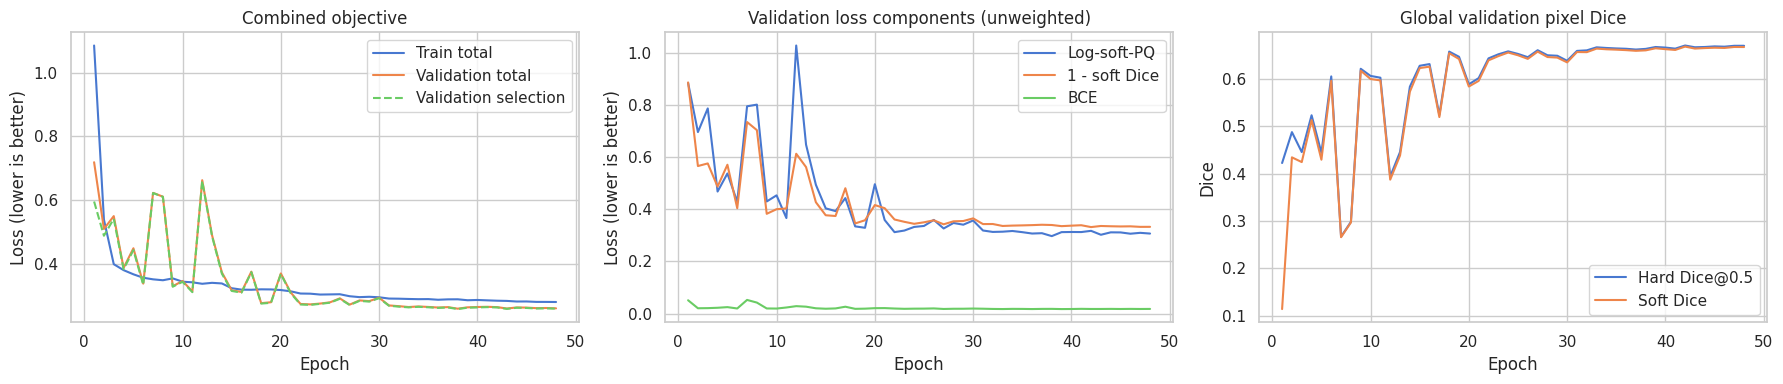

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train total")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation total")
axes[0].plot(
    history_df["epoch"], history_df["val_selection_loss"],
    label="Validation selection", linestyle="--",
)
axes[0].set(title="Combined objective", xlabel="Epoch", ylabel="Loss (lower is better)")
axes[0].legend()
axes[1].plot(history_df["epoch"], history_df["val_log_soft_pq_loss"], label="Log-soft-PQ")
axes[1].plot(history_df["epoch"], 1 - history_df["val_soft_dice"], label="1 - soft Dice")
axes[1].plot(history_df["epoch"], history_df["val_bce_loss"], label="BCE")
axes[1].set(
    title="Validation loss components (unweighted)",
    xlabel="Epoch", ylabel="Loss (lower is better)",
)
axes[1].legend()
axes[2].plot(history_df["epoch"], history_df["val_dice_at_0_5"], label="Hard Dice@0.5")
axes[2].plot(history_df["epoch"], history_df["val_soft_dice"], label="Soft Dice")
axes[2].set(title="Global validation pixel Dice", xlabel="Epoch", ylabel="Dice")
axes[2].legend()
plt.tight_layout()
plt.show()


## Select the threshold for validation PQ and Dice

For each candidate, threshold validation masks, split each tile's binary union mask into connected components, match components by IoU, and accumulate component-PQ and global pixel Dice over validation tiles. This tile-connected-component PQ is a proxy: merged instances and objects crossing tile boundaries can differ from the original annotation instances.

Select the threshold with the highest harmonic mean of measured validation component-PQ and pixel Dice (`validation_joint_score`), using component-PQ, Dice, then the lower threshold to break exact ties. The harmonic mean rewards both metrics; a zero component score gives a zero joint score. An entirely empty prediction and target set scores 1 for both metrics. This sweep runs after checkpoint selection, rather than measuring component-PQ every training epoch.


In [15]:
THRESHOLD_CANDIDATES = (0.20, 0.30, 0.40, 0.50, 0.60, 0.70)
PQ_MATCH_IOU = 0.50
MIN_COMPONENT_AREA = 20
threshold_totals = {
    t: {
        "intersection": 0,
        "predicted_pixels": 0,
        "target_pixels": 0,
        "matched_iou": 0.0,
        "tp": 0,
        "fp": 0,
        "fn": 0,
    }
    for t in THRESHOLD_CANDIDATES
}
threshold_logits = {
    threshold: float(np.log(threshold / (1.0 - threshold)))
    for threshold in THRESHOLD_CANDIDATES
}


def component_map(binary_mask, min_area=MIN_COMPONENT_AREA):
    """Return compact component labels and areas without allocating one mask per object."""
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary_mask.astype(np.uint8, copy=False), connectivity=8
    )
    keep = np.flatnonzero(stats[1:, cv2.CC_STAT_AREA] >= min_area) + 1
    remap = np.zeros(count, dtype=np.int32)
    remap[keep] = np.arange(1, len(keep) + 1, dtype=np.int32)
    return remap[labels], stats[keep, cv2.CC_STAT_AREA].astype(np.int64, copy=False)


def panoptic_quality_counts(prediction, target_components, iou_threshold=PQ_MATCH_IOU):
    """Match components from label-pair counts instead of nested full-mask IoUs."""
    target_labels, target_areas = target_components
    predicted_labels, predicted_areas = component_map(prediction)
    target_count, predicted_count = len(target_areas), len(predicted_areas)
    if not target_count and not predicted_count:
        return {"matched_iou": 0.0, "tp": 0, "fp": 0, "fn": 0}
    if not target_count:
        return {"matched_iou": 0.0, "tp": 0, "fp": predicted_count, "fn": 0}
    if not predicted_count:
        return {"matched_iou": 0.0, "tp": 0, "fp": 0, "fn": target_count}

    valid = (target_labels > 0) & (predicted_labels > 0)
    if not valid.any():
        return {"matched_iou": 0.0, "tp": 0, "fp": predicted_count, "fn": target_count}
    pair_codes = (
        target_labels[valid].astype(np.int64) * (predicted_count + 1)
        + predicted_labels[valid]
    )
    intersections = np.bincount(
        pair_codes, minlength=(target_count + 1) * (predicted_count + 1)
    ).reshape(target_count + 1, predicted_count + 1)[1:, 1:]
    target_indices, predicted_indices = np.nonzero(intersections)
    if not len(target_indices):
        return {"matched_iou": 0.0, "tp": 0, "fp": predicted_count, "fn": target_count}
    overlap = intersections[target_indices, predicted_indices].astype(np.float32)
    union = (
        target_areas[target_indices]
        + predicted_areas[predicted_indices]
        - overlap
    )
    ious = overlap / union
    candidates = np.flatnonzero(ious > iou_threshold)
    matched_targets = np.zeros(target_count, dtype=bool)
    matched_predictions = np.zeros(predicted_count, dtype=bool)
    matched_iou = 0.0
    for candidate in candidates[np.argsort(ious[candidates])[::-1]]:
        target_index = target_indices[candidate]
        predicted_index = predicted_indices[candidate]
        if not matched_targets[target_index] and not matched_predictions[predicted_index]:
            matched_targets[target_index] = True
            matched_predictions[predicted_index] = True
            matched_iou += float(ious[candidate])
    tp = int(matched_targets.sum())
    return {
        "matched_iou": matched_iou,
        "tp": tp,
        "fp": predicted_count - tp,
        "fn": target_count - tp,
    }


def _pq_worker(pair):
    return panoptic_quality_counts(pair[0], pair[1])


gpu_pixel_totals = {
    threshold: {
        "intersection": torch.zeros((), dtype=torch.int64, device=DEVICE),
        "predicted_pixels": torch.zeros((), dtype=torch.int64, device=DEVICE),
        "target_pixels": torch.zeros((), dtype=torch.int64, device=DEVICE),
    }
    for threshold in THRESHOLD_CANDIDATES
}
threshold_started = time.perf_counter()
model.eval()
with ThreadPoolExecutor(max_workers=CPU_POSTPROCESS_WORKERS) as pq_executor:
    with torch.inference_mode():
        for images, targets in CUDAPrefetcher(val_loader):
            with torch.autocast(
                device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED
            ):
                logits = model(images)[:, 0]
            target_gpu = targets[:, 0].bool()
            # Ground-truth components are identical for every candidate threshold.
            target_components = list(
                pq_executor.map(component_map, target_gpu.cpu().numpy())
            )
            for threshold in THRESHOLD_CANDIDATES:
                predicted_gpu = logits.ge(threshold_logits[threshold])
                pixel_totals = gpu_pixel_totals[threshold]
                pixel_totals["intersection"] += torch.logical_and(
                    predicted_gpu, target_gpu
                ).sum()
                pixel_totals["predicted_pixels"] += predicted_gpu.sum()
                pixel_totals["target_pixels"] += target_gpu.sum()
                counts_iter = pq_executor.map(
                    _pq_worker,
                    zip(predicted_gpu.cpu().numpy(), target_components),
                )
                totals = threshold_totals[threshold]
                for counts in counts_iter:
                    for key in ("matched_iou", "tp", "fp", "fn"):
                        totals[key] += counts[key]

torch.cuda.synchronize(DEVICE)
for threshold, pixel_totals in gpu_pixel_totals.items():
    totals = threshold_totals[threshold]
    for key, value in pixel_totals.items():
        totals[key] = int(value.item())

threshold_rows = []
for threshold, totals in threshold_totals.items():
    denominator = totals["tp"] + 0.5 * totals["fp"] + 0.5 * totals["fn"]
    pq = totals["matched_iou"] / denominator if denominator else 1.0
    pixel_dice = (2 * totals["intersection"] + 1.0) / (
        totals["predicted_pixels"] + totals["target_pixels"] + 1.0
    )
    joint_denominator = pq + pixel_dice
    joint_score = 2.0 * pq * pixel_dice / joint_denominator if joint_denominator > 0.0 else 0.0
    threshold_rows.append(
        {
            "threshold": threshold,
            "validation_joint_score": joint_score,
            "validation_component_PQ": pq,
            "validation_pixel_Dice": pixel_dice,
            "TP": totals["tp"],
            "FP": totals["fp"],
            "FN": totals["fn"],
        }
    )
threshold_summary = (
    pd.DataFrame(threshold_rows)
    .sort_values(
        ["validation_joint_score", "validation_component_PQ", "validation_pixel_Dice", "threshold"],
        ascending=[False, False, False, True],
    )
    .reset_index(drop=True)
)
BEST_THRESHOLD = float(threshold_summary.iloc[0]["threshold"])
display(threshold_summary.round(4))
print(
    f"Selected threshold by joint component-PQ / pixel-Dice harmonic mean: {BEST_THRESHOLD:.2f}; "
    f"joint score {threshold_summary.iloc[0]['validation_joint_score']:.4f}; "
    f"selection time {(time.perf_counter() - threshold_started):.1f}s"
)

,threshold,validation_joint_score,validation_component_PQ,validation_pixel_Dice,TP,FP,FN
0,0.7000,0.3816,0.2675,0.6656,896,2212,561
1,0.6000,0.3788,0.2649,0.6647,901,2272,556
2,0.5000,0.3747,0.2610,0.6637,903,2347,554
3,0.4000,0.3702,0.2569,0.6625,902,2418,555
4,0.3000,0.3639,0.2511,0.6609,900,2518,557
5,0.2000,0.3568,0.2446,0.6587,904,2656,553


Selected threshold by joint component-PQ / pixel-Dice harmonic mean: 0.70; joint score 0.3816; selection time 44.5s


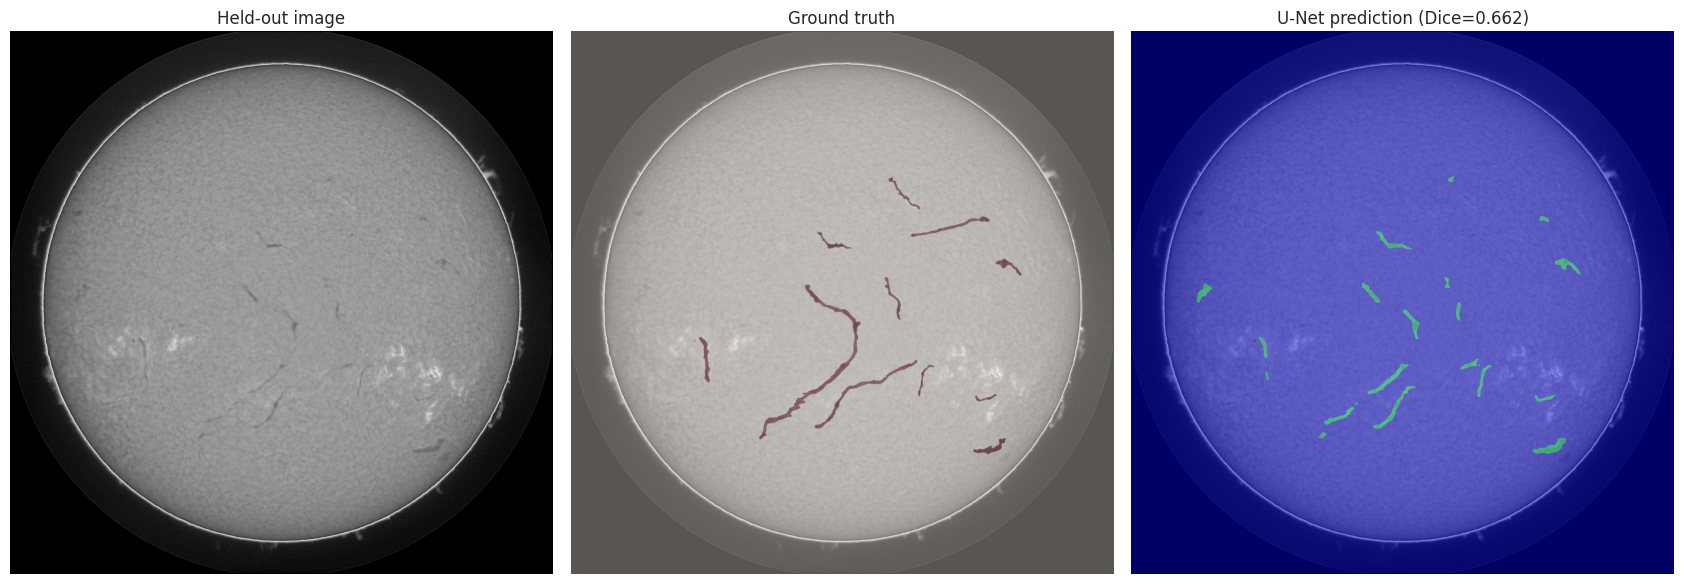

In [16]:
def predict_full_resolution(image, threshold=BEST_THRESHOLD, batch_size=BATCH_SIZE):
    if image.ndim != 2:
        raise ValueError(f"Expected grayscale image, got shape {image.shape}")
    height, width = image.shape
    pad_height, pad_width = (-height) % TILE_SIZE, (-width) % TILE_SIZE
    if pad_height or pad_width:
        mode = (
            cv2.BORDER_REFLECT_101 if min(height, width) > 1 else cv2.BORDER_REPLICATE
        )
        padded = cv2.copyMakeBorder(image, 0, pad_height, 0, pad_width, mode)
    else:
        padded = image
    padded_height, padded_width = padded.shape
    positions = [
        (y, x)
        for y in range(0, padded_height, TILE_SIZE)
        for x in range(0, padded_width, TILE_SIZE)
    ]
    stitched = np.zeros((padded_height, padded_width), dtype=np.uint8)
    if not 0.0 < threshold < 1.0:
        raise ValueError(f"threshold must be in (0, 1), got {threshold}")
    threshold_logit = float(np.log(threshold / (1.0 - threshold)))
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(positions), batch_size):
            batch_positions = positions[start : start + batch_size]
            patches = np.stack(
                [
                    padded[y : y + TILE_SIZE, x : x + TILE_SIZE]
                    for y, x in batch_positions
                ]
            )
            # Transfer compact grayscale uint8 patches, then normalize on the GPU.
            inputs = torch.from_numpy(patches[:, None, ...]).to(DEVICE).float().div_(255.0)
            with torch.autocast(
                device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED
            ):
                predictions = model(inputs)[:, 0].ge(threshold_logit).cpu().numpy()
            for (y, x), prediction in zip(batch_positions, predictions):
                stitched[y : y + TILE_SIZE, x : x + TILE_SIZE] = (
                    prediction.astype(np.uint8)
                )
    return stitched[:height, :width].astype(bool)


# Visualize a held-out validation image at native resolution.
validation_visual_id = val_image_ids[0]
validation_info = next(
    img for img in annotations["images"] if img["id"] == validation_visual_id
)
validation_image = cv2.imread(
    str(TRAIN_IMAGES_DIR / validation_info["file_name"]), cv2.IMREAD_GRAYSCALE
)
validation_target, _ = polygons_to_mask(validation_visual_id, annotations)
validation_prediction = predict_full_resolution(validation_image)
intersection = np.logical_and(validation_prediction, validation_target > 0).sum()
denominator = validation_prediction.sum() + (validation_target > 0).sum()
image_dice = (2 * intersection + 1.0) / (denominator + 1.0)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
axes[0].imshow(validation_image, cmap="gray")
axes[0].set_title("Held-out image")
axes[1].imshow(validation_image, cmap="gray")
axes[1].imshow(validation_target, cmap="Reds", alpha=0.35)
axes[1].set_title("Ground truth")
axes[2].imshow(validation_image, cmap="gray")
axes[2].imshow(validation_prediction, cmap="winter", alpha=0.4)
axes[2].set_title(f"U-Net prediction (Dice={image_dice:.3f})")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## Generate the competition submission

Submission formatting follows the YOLO notebook: split the binary prediction into 8-connected components, discard components smaller than 20 pixels, sort by descending area (then top/left position), assign IDs as image-stem plus component number, and encode each component with pycocotools in Fortran order.


In [17]:
MIN_COMPONENT_AREA = 20
CREATE_SUBMISSION = True


def get_test_image_paths():
    suffixes = {".jpg", ".jpeg", ".png"}
    paths = [
        p
        for p in TEST_IMAGES_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in suffixes
    ]
    return sorted(paths, key=lambda path: path.name)


def split_into_filaments(binary_mask, min_area=MIN_COMPONENT_AREA):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary_mask.astype(np.uint8), connectivity=8
    )
    components = []
    for label in range(1, count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area >= min_area:
            top = int(stats[label, cv2.CC_STAT_TOP])
            left = int(stats[label, cv2.CC_STAT_LEFT])
            components.append((area, top, left, labels == label))
    components.sort(key=lambda item: (-item[0], item[1], item[2]))
    return [item[3] for item in components]


def mask_to_rle(binary_mask):
    encoded = mask_utils.encode(np.asfortranarray(binary_mask.astype(np.uint8)))
    return encoded["counts"].decode("utf-8")


def encode_prediction_rows(path_stem, binary_mask):
    components = split_into_filaments(binary_mask, MIN_COMPONENT_AREA)
    return [
        (f"{path_stem}_{index}", mask_to_rle(component))
        for index, component in enumerate(components, start=1)
    ]


def create_submission(output_path=SUBMISSION_PATH):
    image_paths = get_test_image_paths()
    if not image_paths:
        raise FileNotFoundError(f"No test images found in {TEST_IMAGES_DIR}")
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    if DEVICE.type == "cpu":
        # Leave CPU cores available while RLE workers run beside inference.
        torch.set_num_threads(max(1, CPU_COUNT - CPU_POSTPROCESS_WORKERS))

    start_time = time.perf_counter()
    total_rows = 0
    seen_ids = set()
    pending = deque()

    with ThreadPoolExecutor(max_workers=CPU_POSTPROCESS_WORKERS) as executor:
        with output_path.open("w", newline="", encoding="utf-8") as submission_file:
            writer = csv.writer(submission_file)
            writer.writerow(["filament_id", "segmentation_rle"])

            def write_oldest_result():
                nonlocal total_rows
                _, future = pending.popleft()
                for filament_id, rle in future.result():
                    if filament_id in seen_ids:
                        raise ValueError(f"Duplicate filament ID: {filament_id}")
                    seen_ids.add(filament_id)
                    writer.writerow([filament_id, rle])
                    total_rows += 1

            for index, image_path in enumerate(image_paths, start=1):
                image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
                if image is None:
                    raise OSError(f"Could not read test image: {image_path}")
                prediction = predict_full_resolution(image, threshold=BEST_THRESHOLD)
                future = executor.submit(
                    encode_prediction_rows, image_path.stem, prediction
                )
                pending.append((image_path.stem, future))
                del prediction, image

                # Bound queued full-resolution masks while CPU RLE work overlaps inference.
                if len(pending) >= MAX_PENDING_POSTPROCESS:
                    write_oldest_result()
                if index % 20 == 0 or index == len(image_paths):
                    print(
                        f"Inference {index:,}/{len(image_paths):,}; "
                        f"rows written {total_rows:,}; queued CPU tasks {len(pending)}",
                        flush=True,
                    )

            while pending:
                write_oldest_result()

    print(
        f"Submission saved: {output_path}\nTest images: {len(image_paths):,}; "
        f"filament rows: {total_rows:,}; elapsed: {(time.perf_counter() - start_time) / 60:.1f} min"
    )
    return output_path


if CREATE_SUBMISSION:
    create_submission()
else:
    print(f"Set CREATE_SUBMISSION=True to write {SUBMISSION_PATH}")

Inference 20/180; rows written 217; queued CPU tasks 7
Inference 40/180; rows written 743; queued CPU tasks 7
Inference 60/180; rows written 1,240; queued CPU tasks 7
Inference 80/180; rows written 1,786; queued CPU tasks 7
Inference 100/180; rows written 2,351; queued CPU tasks 7
Inference 120/180; rows written 2,802; queued CPU tasks 7
Inference 140/180; rows written 3,068; queued CPU tasks 7
Inference 160/180; rows written 3,286; queued CPU tasks 7
Inference 180/180; rows written 3,497; queued CPU tasks 7
Submission saved: /kaggle/working/solar_filament_unet_submission.csv
Test images: 180; filament rows: 3,629; elapsed: 0.9 min


In [18]:
# Stream through the CSV and check its schema, IDs, and a decodable sample RLE.
submission_columns = None
submission_row_count = 0
null_row_count = 0
duplicate_id_count = 0
empty_value_count = 0
seen_ids = set()
sample_rle_decodable = False

if CREATE_SUBMISSION:
    with SUBMISSION_PATH.open("r", newline="", encoding="utf-8") as submission_file:
        reader = csv.DictReader(submission_file)
        submission_columns = reader.fieldnames
        for row in reader:
            submission_row_count += 1
            filament_id = row.get("filament_id")
            rle = row.get("segmentation_rle")
            if any(value is None for value in row.values()):
                null_row_count += 1
            if not filament_id or not rle:
                empty_value_count += 1
            if filament_id in seen_ids:
                duplicate_id_count += 1
            elif filament_id:
                seen_ids.add(filament_id)
            if submission_row_count == 1 and rle:
                try:
                    decoded = mask_utils.decode(
                        {
                            "size": [IMAGE_HEIGHT, IMAGE_WIDTH],
                            "counts": rle.encode("utf-8"),
                        }
                    )
                    sample_rle_decodable = decoded.shape == (
                        IMAGE_HEIGHT,
                        IMAGE_WIDTH,
                    ) and bool(decoded.any())
                except Exception:
                    sample_rle_decodable = False

submission_valid = (
    submission_columns == ["filament_id", "segmentation_rle"]
    and null_row_count == 0
    and duplicate_id_count == 0
    and empty_value_count == 0
    and (sample_rle_decodable or submission_row_count == 0)
)
print("--- Submission audit ---")
print(f"Columns: {submission_columns}")
print(f"Rows: {submission_row_count:,}")
print(f"Null rows: {null_row_count:,}")
print(f"Duplicate IDs: {duplicate_id_count:,}")
print(f"Empty IDs/RLE: {empty_value_count:,}")
print(f"Sample RLE decodes to {IMAGE_HEIGHT}x{IMAGE_WIDTH}: {sample_rle_decodable}")
print(
    "[VERIFIED] Submission structure passed."
    if submission_valid
    else "[WARNING] Submission needs inspection."
)

--- Submission audit ---
Columns: ['filament_id', 'segmentation_rle']
Rows: 3,629
Null rows: 0
Duplicate IDs: 0
Empty IDs/RLE: 0
Sample RLE decodes to 2048x2048: True
[VERIFIED] Submission structure passed.


## Outputs

- `solar_filament_tiles/`: generated 512 x 512 image and mask tiles with split metadata.
- `unet_outputs/custom_unet_best.pth`: custom U-Net checkpoint selected by combined validation loss with hard Dice at 0.5.
- `unet_outputs/training_history.csv`: epoch-level combined train/validation losses; separate log-soft-PQ and BCE losses; global soft Dice and validation hard Dice at 0.5 (training hard Dice is left blank to avoid extra reductions); validation selection loss; timings and throughput.
- `solar_filament_unet_submission.csv`: competition rows in `filament_id, segmentation_rle` format.

Training uses one persistent process per GPU with DistributedDataParallel and four total Kaggle loader workers. Packed grayscale uint8 tiles share OS cache pages across all processes. Layout selection runs on the target GPUs. Each epoch records separate training and validation durations and throughput; the first epoch prints per-GPU forward, combined-loss calculation, backward, optimizer, and VRAM measurements after warmup. The worker script and `distributed_training.log` are written under `unet_outputs`. The best checkpoint returns to the notebook automatically for grayscale inference.
